<p align="center"><img src="assets/hero.svg" width="100%" alt="Gün 1 — Perceptron’dan Kaybolan Gradyana"></p>
<p align="center">
<img src="https://img.shields.io/badge/Gün-01-7C3AED?style=for-the-badge" alt="Gün 01">
<img src="https://img.shields.io/badge/Konu-Sinir_Ağları_Temeli-22D3EE?style=for-the-badge" alt="Sinir ağları temeli">
<img src="https://img.shields.io/badge/NumPy-013243?style=for-the-badge&amp;logo=numpy&amp;logoColor=white" alt="NumPy">
<img src="https://img.shields.io/badge/Matplotlib-11557C?style=for-the-badge" alt="Matplotlib">
<img src="https://img.shields.io/badge/Seviye-Sıfırdan-34D399?style=for-the-badge" alt="Sıfırdan">
</p>

<table><tr>
<td width="25%" align="center" valign="top"><h3>🧠</h3><b>Perceptron</b><br><br>Tek bir nöron<br>ağırlık · bias · aktivasyon<br><br></td>
<td width="25%" align="center" valign="top"><h3>🏗️</h3><b>Yapay Sinir Ağı</b><br><br>Katmanlar<br>forward propagation<br><br></td>
<td width="25%" align="center" valign="top"><h3>🔁</h3><b>Backpropagation</b><br><br>Loss · gradient descent<br>learning rate · zincir kuralı<br><br></td>
<td width="25%" align="center" valign="top"><h3>🤫</h3><b>Vanishing Gradient</b><br><br>Kaybolan gradyan<br>fısıltı oyunu ve çözümler<br><br></td>
</tr></table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="hedef">

**Bu notebook sonunda şunları yapabileceksin:**

- Bir **perceptron**un (tek yapay nöron) içinde ne olduğunu, kalem kâğıtla ve kodla hesaplayacaksın.
- **Ağırlık, bias, aktivasyon** kavramlarını günlük hayattan örneklerle açıklayacaksın.
- Neden tek nöronun yetmediğini, **çok katmanlı yapay sinir ağının (ANN)** neden gerektiğini göreceksin.
- Bir tahminin ağın içinde nasıl yol aldığını (**forward propagation**) sayı sayı izleyeceksin.
- Ağın **hatasından nasıl öğrendiğini** (**loss, gradient descent, backpropagation, zincir kuralı**) adım adım çözeceksin.
- Derin ağlarda öğrenmeyi neden **kaybolan gradyanın** (vanishing gradient) durdurduğunu ve çözümlerini anlayacaksın.

**Ön koşul:** Yok. Python’da `print` yazabilmen yeterli; tüm terimler geçtikleri yerde açıklanıyor.

**YBS gözüyle:** Her bölümde kavramı bir işletme/öğrenci hayatı örneğine bağlıyoruz: kredi ön eleme, ağırlıklı not ortalaması, geçme barajı, şirket hiyerarşisi, fısıltı oyunu.

</td></tr></table>

<p align="center"><img src="assets/yol_haritasi.svg" width="100%" alt="Gün 1 yol haritası: 14 durak"></p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Durak | Bölüm |
|:--:|:--|:--:|:--|
| 1 | [Büyük Resim](#b1) | 8 | [Forward Propagation](#b8) |
| 2 | [Perceptron Anatomisi](#b2) | 9 | [Loss: Ne Kadar Yanlışız?](#b9) |
| 3 | [Ağırlıklı Toplam](#b3) | 10 | [Gradient Descent](#b10) |
| 4 | [Bias ve Eşik](#b4) | 11 | [Backpropagation](#b11) |
| 5 | [Aktivasyon Fonksiyonu](#b5) | 12 | [Vanishing Gradient](#b12) |
| 6 | [Doğrusal Sınır](#b6) | 13 | [Çözüm Yolları](#b13) |
| 7 | [Çok Katmanlı Ağ (ANN)](#b7) | 14 | [Kapanış: Özet, Sınav, Görevler](#b14) |

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="not">

Notebook’u `day01/` klasörü içinden çalıştırın; grafikler `outputs/figures/` klasörüne kaydedilir. Yalnızca **NumPy, Matplotlib ve pandas** kullanıyoruz, yani derin öğrenme kütüphanesi (PyTorch, TensorFlow) yok. Amaç: sihirli kutuyu açıp **içinde ne olduğunu kendi elimizle hesaplamak**.

Kurulum gerekirse: `pip install numpy matplotlib pandas ipykernel`.

**Kaynak:** Bu notlar, Atıl SAMANCIOĞLU’nun **“Derin Öğrenme 2026: 100 Günlük Kamp”** Udemy kursundaki 4 ders dokümanından (Perceptron, ANN Giriş, Backpropagation, Vanishing Gradient) alıntıdır; anlatım, analoji, animasyon ve ek deneyler bu notebook’a özgüdür. Kaynakta olmayan ek örnekler ayrıca **“ek örnek”** diye işaretlenmiştir.

</td></tr></table>

### 🧰 Kurulum: Kütüphaneler ve Görsel Tema

Önce araçlarımızı alıyoruz. **NumPy** sayı hesaplama, **Matplotlib** grafik, **pandas** ise tablo için. Grafiklerin hepsi aynı koyu tema ve aynı renk diliyle çizilecek: **mor = perceptron/veri, camgöbeği = ağ/ileri akış, gül = hata/geri akış, kehribar = uyarı/bias, yeşil = doğru/başarı.**

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns', 20)

FIG_DIR = Path('outputs/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Tüm grafiklerde aynı anlam, aynı renk
RENK = {'mor': '#A78BFA', 'cam': '#22D3EE', 'amber': '#FBBF24', 'gul': '#FB7185', 'yesil': '#34D399',
        'metin': '#F8FAFC', 'soluk': '#94A3B8', 'zemin': '#0B1026', 'panel': '#111936', 'izgara': '#334155'}

mpl.rcParams.update({
    'figure.facecolor': RENK['zemin'], 'axes.facecolor': RENK['panel'], 'savefig.facecolor': RENK['zemin'],
    'axes.edgecolor': RENK['izgara'], 'axes.labelcolor': RENK['soluk'], 'xtick.color': RENK['soluk'],
    'ytick.color': RENK['soluk'], 'text.color': RENK['metin'], 'axes.titlecolor': RENK['metin'],
    'grid.color': RENK['izgara'], 'grid.alpha': 0.55, 'grid.linestyle': ':', 'axes.grid': True,
    'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 11.5, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11.5,
    'figure.dpi': 110, 'savefig.dpi': 160, 'savefig.bbox': 'tight', 'mathtext.fontset': 'dejavusans',
    'legend.facecolor': RENK['panel'], 'legend.edgecolor': RENK['izgara'], 'legend.labelcolor': RENK['metin'],
    'font.family': 'DejaVu Sans',
})


def baslik(fig, ana, alt=None, ust=0.80):
    """Grafiğe 'içgörü cümlesi' başlığı + açıklayıcı alt başlık ekler."""
    fig.subplots_adjust(top=ust)
    fig.text(0.012, 0.985, ana, fontsize=17, fontweight='bold', color=RENK['metin'], va='top', ha='left')
    if alt:
        fig.text(0.012, 0.985 - 0.095 * (5.0 / fig.get_figheight()), alt, fontsize=11.5, color=RENK['soluk'], va='top', ha='left')


def kaydet(fig, ad):
    fig.savefig(FIG_DIR / f'{ad}.png')
    plt.show()


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def sigmoid_turev(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def step(z):
    return np.where(np.asarray(z) > 0, 1, 0)


print('Hazır. NumPy', np.__version__, '· Matplotlib', mpl.__version__, '· pandas', pd.__version__)

Hazır. NumPy 2.3.3 · Matplotlib 3.10.6 · pandas 2.3.0


<a id="b1"></a>

<p align="center"><img src="assets/bolum_01.svg" width="100%" alt="Bölüm 1 — Büyük Resim"></p>

### 🎭 Önce bir benzetme: Tarif mi, deneyim mi?

Bir kafede çalıştığını düşün. Yeni gelen stajyere “**yoğun saat ne zaman?**” sorusunu iki şekilde öğretebilirsin:

1. **Kural yazarak:** “Hafta içi 12:00–13:30 arası ve 17:00–18:00 arası yoğundur, yağmurlu günlerde %20 artar…” (Sayısız istisna çıkar, liste bitmez.)
2. **Deneyim göstererek:** Ona 2 yıllık satış kayıtlarını verirsin; stajyer **örüntüyü kendisi çıkarır.**

**Makine öğrenmesi ikincisidir:** kuralları insan yazmaz, makine örneklerden öğrenir. **Yapay sinir ağları** da bu öğrenmeyi yapan, beynimizdeki nöronlardan *esinlenmiş* matematiksel yapılardır.

<table><tr><td>

<img src="assets/etiket_ybs.svg" height="34" alt="ybs">

**YBS örneği, kredi ön değerlendirmesi:** Bir banka başvuruları “gelir, yaş, borç” bilgisine bakıp **onay / ret** kararı veriyor. Kuralı elle yazmak yerine, geçmiş binlerce başvurudan öğrenen bir model kullanırsan bu bir **makine öğrenmesi**; modelin içinde sinir ağı varsa **derin öğrenme** tarafındasın.

</td></tr></table>

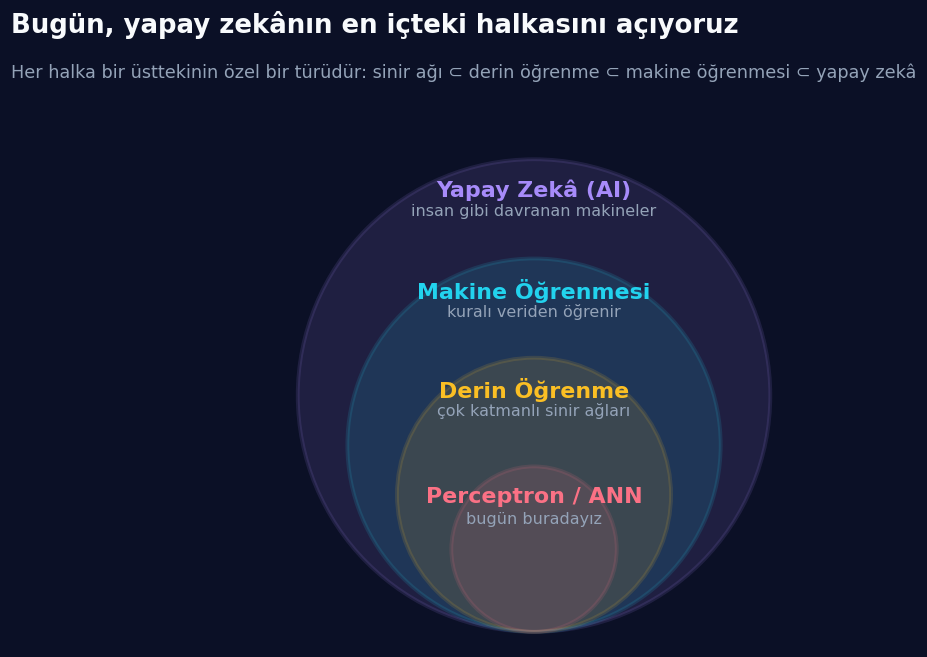

In [2]:
# Kavramların iç içe geçmiş hali: AI > Makine Öğrenmesi > Derin Öğrenme > Sinir Ağı
fig, ax = plt.subplots(figsize=(9.5, 6.6))
ax.set_aspect('equal'); ax.axis('off'); ax.grid(False)

halkalar = [
    (5.0, RENK['mor'], 'Yapay Zekâ (AI)', 'insan gibi davranan makineler'),
    (3.95, RENK['cam'], 'Makine Öğrenmesi', 'kuralı veriden öğrenir'),
    (2.9, RENK['amber'], 'Derin Öğrenme', 'çok katmanlı sinir ağları'),
    (1.75, RENK['gul'], 'Perceptron / ANN', 'bugün buradayız'),
]
for r, renk, ad, aciklama in halkalar:
    ax.add_patch(plt.Circle((0, r - 5.0), r, facecolor=renk, alpha=0.13, edgecolor=renk, linewidth=2.5))
    ax.text(0, 2 * r - 5.0 - 0.42, ad, ha='center', va='top', fontsize=14.5, fontweight='bold', color=renk)
    ax.text(0, 2 * r - 5.0 - 0.95, aciklama, ha='center', va='top', fontsize=10.5, color=RENK['soluk'])
ax.set_xlim(-5.2, 5.2); ax.set_ylim(-5.3, 5.3)
baslik(fig, 'Bugün, yapay zekânın en içteki halkasını açıyoruz', 'Her halka bir üsttekinin özel bir türüdür: sinir ağı ⊂ derin öğrenme ⊂ makine öğrenmesi ⊂ yapay zekâ', ust=0.80)
kaydet(fig, '01_ic_ice_halkalar')

### 📖 Mini Sözlük 1: Veri Tarafı

<table><tr>
<td width="33%" valign="top"><h4>🔢 Girdi / Özellik</h4><i>(input, feature)</i><br><br>Modele verdiğimiz bilgiler. Bizde: <b>IQ</b> ve <b>günlük çalışma süresi</b>. Matematikte <code>x₁, x₂, …</code> diye yazılır.<br><br>🎭 <i>Başvuru formundaki kutucuklar.</i></td>
<td width="33%" valign="top"><h4>🏷️ Çıktı / Etiket</h4><i>(output, label)</i><br><br>Tahmin etmek istediğimiz şey. Bizde: dersten <b>geçti (1)</b> mi <b>kaldı (0)</b> mı? Gerçek değere <code>y</code>, modelin tahminine <code>ŷ</code> (“y şapka”) denir.<br><br>🎭 <i>Sınav sonuç belgesi.</i></td>
<td width="33%" valign="top"><h4>🎯 İkili Sınıflandırma</h4><i>(binary classification)</i><br><br>Cevabı iki seçenekten biri olan problemler: geçti/kaldı, onay/ret, spam/spam değil. Yani <code>y ∈ {0, 1}</code>.<br><br>🎭 <i>Evet / Hayır sorusu.</i></td>
</tr></table>

### 📖 Mini Sözlük 2: Model Tarafı

<table><tr>
<td width="25%" valign="top"><h4>⚖️ Ağırlık</h4><i>(weight, w)</i><br><br>Her girdinin kararda <b>ne kadar önemli</b> olduğunu söyleyen sayı.<br><br>🎭 <i>Derste kredisi yüksek olan dersin ortalamaya etkisi.</i></td>
<td width="25%" valign="top"><h4>🎚️ Bias</h4><i>(b)</i><br><br>Girdilerden bağımsız <b>sabit bir kaydırma</b>; kararın başlangıç eğilimi.<br><br>🎭 <i>Geçme barajı.</i></td>
<td width="25%" valign="top"><h4>🚦 Aktivasyon</h4><i>(activation function)</i><br><br>Ham skoru <b>karara</b> çeviren fonksiyon.<br><br>🎭 <i>Işık anahtarı.</i></td>
<td width="25%" valign="top"><h4>🧠 Nöron</h4><i>(neuron)</i><br><br>Tartıp topla, sonra aktivasyondan geçir; ağın en küçük işlem birimi.<br><br>🎭 <i>Tek bir jüri üyesi.</i></td>
</tr><tr>
<td width="25%" valign="top"><h4>📏 Loss</h4><i>(kayıp, hata)</i><br><br>Tahminin gerçekten <b>ne kadar uzak</b> olduğunu gösteren tek sayı.<br><br>🎭 <i>Dart atışında hedefe uzaklık.</i></td>
<td width="25%" valign="top"><h4>⛰️ Gradyan</h4><i>(gradient, ∂L/∂w)</i><br><br>Bir ağırlığı biraz oynatsak loss <b>hangi yönde, ne kadar</b> değişir?<br><br>🎭 <i>Ayağının altındaki yamacın eğimi.</i></td>
<td width="25%" valign="top"><h4>👣 Öğrenme Oranı</h4><i>(learning rate, η)</i><br><br>Her adımda <b>ne kadar büyük</b> düzeltme yapacağımız.<br><br>🎭 <i>Adım uzunluğu.</i></td>
<td width="25%" valign="top"><h4>🔁 Backpropagation</h4><i>(geri yayılım)</i><br><br>Hatayı geriye taşıyıp <b>her ağırlığın suçunu</b> hesaplama.<br><br>🎭 <i>Üretim hattında hatanın kaynağını geriye doğru aramak.</i></td>
</tr></table>

### 👩‍🎓 Bu Notebook Boyunca Takip Edeceğimiz Öğrenciler

Kaynak dokümanda, bir öğrencinin **dersten geçip geçmeyeceğini** iki bilgiye bakarak tahmin ediyoruz: **IQ** (`x₁`) ve **günlük çalışma süresi** (`x₂`, saat). Çıktı ikilidir: `y = 1` geçti, `y = 0` kaldı. Doküman 3 öğrenciyi örnek veriyor, bir de **takip edeceğimiz özel bir öğrenci**: `x₁ = 100`, `x₂ = 4`.

In [3]:
# Kaynaktaki 3 örnek öğrenci: [IQ, günlük çalışma saati]
X = np.array([[95, 3],
              [110, 4],
              [100, 5]], dtype=float)
y = np.array([0, 1, 1])             # 0 = kaldı, 1 = geçti

# Bu notebook boyunca takip edeceğimiz öğrenci
takip = np.array([100, 4], dtype=float)

tablo = pd.DataFrame({'IQ (x₁)': X[:, 0].astype(int), 'Çalışma saati (x₂)': X[:, 1].astype(int),
                      'Sonuç (y)': y, 'Anlamı': np.where(y == 1, 'Geçti', 'Kaldı')},
                     index=['Öğrenci A', 'Öğrenci B', 'Öğrenci C'])
display(tablo)
print(f'Takip öğrencisi → IQ = {int(takip[0])}, günlük çalışma = {int(takip[1])} saat')

,IQ (x₁),Çalışma saati (x₂),Sonuç (y),Anlamı
Öğrenci A,95,3,0,Kaldı
Öğrenci B,110,4,1,Geçti
Öğrenci C,100,5,1,Geçti


Takip öğrencisi → IQ = 100, günlük çalışma = 4 saat


<a id="b2"></a>

<p align="center"><img src="assets/bolum_02.svg" width="100%" alt="Bölüm 2 — Perceptron Anatomisi"></p>

### 🎭 Benzetme: Sınav komisyonunda tek bir jüri üyesi

**Perceptron**, yapay sinir ağlarının en sade yapı taşıdır: **tek bir nörondan** oluşur. Bir jüri üyesi gibi düşün: önüne öğrencinin dosyası gelir (**IQ ve çalışma süresi**). Jüri üyesi:

1. Her kritere **önem katsayısı** verir (“çalışma saati benim için IQ’dan daha önemli”),
2. Hepsini **tartıp toplar**, kendi **sertliğini** (baraj) de ekler/çıkarır,
3. Sonunda **tek bir karar** verir: *geçti / kaldı.*

Aşağıdaki animasyonda bizim takip öğrencimizin (**IQ=100, çalışma=4 saat**) bu jüri üyesinin içinde nasıl yol aldığını izle:

<p align="center"><img src="assets/perceptron_anim.svg" width="100%" alt="Animasyon: tek bir perceptronun içinde veri akışı"></p>

### 🔬 Perceptron’un 5 Parçası

| Parça | Sembol | Ne yapar? | Günlük hayat karşılığı |
|:--|:--:|:--|:--|
| **Girdiler** | `x₁, x₂` | Veriyi içeri taşır, hesap yapmaz | Öğrenci dosyasındaki bilgiler |
| **Ağırlıklar** | `w₁, w₂` | Her girdinin önemini belirler | Derslerin kredi katsayısı |
| **Bias** | `b` | Karara sabit bir kayma ekler | Geçme barajı |
| **Toplam** | `z` | `w₁x₁ + w₂x₂ + b` (ham skor) | Ağırlıklı not ortalaması |
| **Aktivasyon** | `f(z)` | Ham skoru karara çevirir | Işık anahtarı |

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**Neden “tek katmanlı” deniyor?** Girdi kısmı sadece veriyi taşır, hesap yapmaz, bu yüzden ayrı bir katman sayılmaz. Asıl hesap **tek bir nöronda** olur. Bu yüzden perceptron literatürde *single-layer neural network* (tek katmanlı sinir ağı) diye geçer.

</td></tr></table>

<a id="b3"></a>

<p align="center"><img src="assets/bolum_03.svg" width="100%" alt="Bölüm 3 — Ağırlıklı Toplam"></p>

### 🎭 Benzetme: Ağırlıklı Not Ortalaması (AGNO)

YBS öğrencisi olarak **ağırlıklı not ortalamasını** zaten biliyorsun: 6 AKTS’lik dersin notu, 2 AKTS’lik dersten **daha çok** etkiler. Perceptron’un yaptığı da bu:

> **z = w₁·x₁ + w₂·x₂ + b**

Her girdi kendi ağırlığıyla çarpılır, hepsi toplanır, üstüne bias eklenir. Kaynak dokümandaki örnek sayılar:

- `w₁ = 0.04` (IQ’nun ağırlığı), `w₂ = 0.6` (çalışma saatinin ağırlığı), `b = −5`
- Takip öğrencisi: `x₁ = 100`, `x₂ = 4`

In [4]:
# Takip öğrencisi ve kaynaktaki örnek ağırlıklar
x1, x2 = 100, 4
w1, w2, b = 0.04, 0.6, -5

katki_iq = w1 * x1            # IQ'nun toplam skora katkısı
katki_calisma = w2 * x2       # Çalışma saatinin katkısı
z = katki_iq + katki_calisma + b

print(f'IQ katkısı        : {w1} × {x1} = {katki_iq}')
print(f'Çalışma katkısı   : {w2} × {x2} = {katki_calisma}')
print(f'Bias              : {b}')
print(f'Ham skor z        : {katki_iq} + {katki_calisma} + ({b}) = {z:.1f}')

IQ katkısı        : 0.04 × 100 = 4.0
Çalışma katkısı   : 0.6 × 4 = 2.4
Bias              : -5
Ham skor z        : 4.0 + 2.4 + (-5) = 1.4


<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="dikkat">

**z henüz bir karar değildir!** `z = 1.4` bize “geçti mi kaldı mı?” demiyor; sadece modelin ürettiği **ham skor**. Pozitif olması “geçme” yönünde, negatif olması “kalma” yönünde bir işaret. Kararı verecek olan sonraki adım: **aktivasyon fonksiyonu** (Bölüm 5).

</td></tr></table>

### 🧪 Mini Deney: Ağırlığı Değiştirirsek Ne Olur?

Ağırlık, bir girdinin kararda **ne kadar söz sahibi** olduğunu belirler. Çalışma saatinin ağırlığını (`w₂`) değiştirelim, IQ’yu ve bias’ı sabit tutalım:

In [5]:
for w2_deneme in [0.0, 0.3, 0.6, 1.2]:
    z_deneme = w1 * x1 + w2_deneme * x2 + b
    karar = 'Geçti ✅' if z_deneme > 0 else 'Kaldı ❌'
    print(f'w₂ = {w2_deneme:>3}  →  z = {z_deneme:>5.2f}  →  {karar}')

w₂ = 0.0  →  z = -1.00  →  Kaldı ❌
w₂ = 0.3  →  z =  0.20  →  Geçti ✅
w₂ = 0.6  →  z =  1.40  →  Geçti ✅
w₂ = 1.2  →  z =  3.80  →  Geçti ✅


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="sonuc">

`w₂ = 0` iken model çalışmayı **tamamen görmezden geliyor** ve takip öğrencisini “kaldı” sayıyor. `w₂` büyüdükçe çalışma saati kararda daha fazla söz sahibi oluyor. **Öğrenme, bu ağırlıkların doğru değerlerini otomatik bulma işidir**; ileride göreceğimiz her şey bunun için.

</td></tr></table>

<a id="b4"></a>

<p align="center"><img src="assets/bolum_04.svg" width="100%" alt="Bölüm 4 — Bias ve Eşik"></p>

### 🎭 Benzetme: Geçme Barajı

Bir derste “vize+final ortalaması 50 ve üstü geçer” kuralı varsa, **50 bir baraj**dır. Notların toplamı ne kadar olursa olsun karar, bu sabit eşiğe göre verilir. **Bias tam olarak bu barajdır**: girdilerden bağımsız, sabit bir kaydırma.

**Teknik olarak:** Bias, karar sınırının **orijinden (0,0) geçmesini engeller.** Bias olmasaydı:

- Model **esnek karar veremezdi** (çizgi hep orijinden geçmek zorunda kalırdı),
- **Öğrenme kapasitesini kaybederdi.**

Bias, lineer regresyondaki **intercept (kesişim)** kavramıyla birebir aynıdır.

Perceptron’un karar sınırı `z = 0` olduğu yerdedir: yani `0.04·IQ + 0.6·saat + b = 0` denklemini sağlayan noktalar. Bu bir **doğru** çizer (IQ–saat düzleminde). Doğrunun bir tarafı “geçti”, diğer tarafı “kaldı” bölgesidir. Bias’ı değiştirince bu doğru **yukarı aşağı kayar.** Üç farklı bias’a bakalım:

- `b = 0`: bias yok (doğru orijinden geçer),
- `b = −5`: kaynaktaki değer,
- `b = −5.8`: kendi elle ayarladığımız değer (**öğrenmiş bir değer değil**, sadece kaydırmanın etkisini göstermek için).

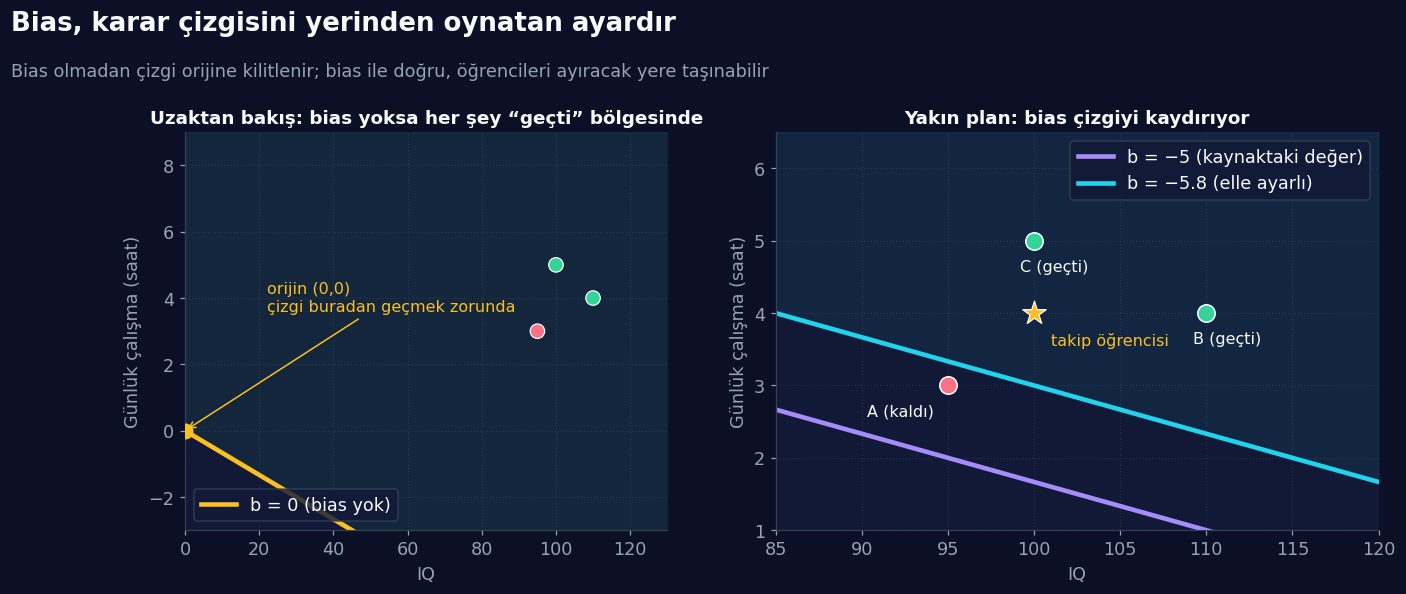

In [6]:
def sinir_cizgisi(iq, w1, w2, b):
    """z = 0 doğrusunda saat değeri: w1*IQ + w2*saat + b = 0"""
    return -(w1 * iq + b) / w2

fig, eksenler = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1, 1.25]})

# Sol: uzaktan bakış (orijin görünsün)
ax = eksenler[0]
iq = np.linspace(0, 130, 200)
ax.plot(iq, sinir_cizgisi(iq, 0.04, 0.6, 0), color=RENK['amber'], lw=3, label='b = 0 (bias yok)')
ax.scatter([0], [0], s=90, color=RENK['amber'], zorder=5)
ax.annotate('orijin (0,0)\nçizgi buradan geçmek zorunda', (0, 0), xytext=(22, 3.6), color=RENK['amber'], fontsize=10.5,
            arrowprops=dict(arrowstyle='->', color=RENK['amber']))
ax.scatter(X[:, 0], X[:, 1], c=[RENK['gul'] if t == 0 else RENK['yesil'] for t in y], s=90, zorder=4, edgecolor='white', linewidth=0.8)
ax.fill_between(iq, sinir_cizgisi(iq, 0.04, 0.6, 0), 9, color=RENK['yesil'], alpha=0.07)
ax.set_xlim(0, 130); ax.set_ylim(-3, 9)
ax.set_xlabel('IQ'); ax.set_ylabel('Günlük çalışma (saat)')
ax.set_title('Uzaktan bakış: bias yoksa her şey “geçti” bölgesinde', fontsize=12)
ax.legend(loc='lower left')

# Sağ: yakın plan
ax = eksenler[1]
iq = np.linspace(85, 120, 200)
ax.plot(iq, sinir_cizgisi(iq, 0.04, 0.6, -5.0), color=RENK['mor'], lw=3, label='b = −5 (kaynaktaki değer)')
ax.plot(iq, sinir_cizgisi(iq, 0.04, 0.6, -5.8), color=RENK['cam'], lw=3, label='b = −5.8 (elle ayarlı)')
ax.fill_between(iq, sinir_cizgisi(iq, 0.04, 0.6, -5.8), 6.5, color=RENK['cam'], alpha=0.07)
for (xi, yi), t, ad in zip(X, y, ['A', 'B', 'C']):
    ax.scatter(xi, yi, s=130, color=RENK['yesil'] if t else RENK['gul'], edgecolor='white', linewidth=1, zorder=5)
    ax.text(xi - 0.8, yi - 0.42, f'{ad} ({"geçti" if t else "kaldı"})', color=RENK['metin'], fontsize=10.5, ha='right' if ad == 'A' else 'left')
ax.scatter(*takip, s=260, marker='*', color=RENK['amber'], edgecolor='white', linewidth=0.8, zorder=6)
ax.text(takip[0] + 1.0, takip[1] - 0.45, 'takip öğrencisi', color=RENK['amber'], fontsize=10.5)
ax.set_xlim(85, 120); ax.set_ylim(1, 6.5)
ax.set_xlabel('IQ'); ax.set_ylabel('Günlük çalışma (saat)')
ax.set_title('Yakın plan: bias çizgiyi kaydırıyor', fontsize=12)
ax.legend(loc='upper right')

baslik(fig, 'Bias, karar çizgisini yerinden oynatan ayardır', 'Bias olmadan çizgi orijine kilitlenir; bias ile doğru, öğrencileri ayıracak yere taşınabilir', ust=0.78)
kaydet(fig, '04_bias_karar_cizgisi')

In [7]:
# Bu iki bias ayarı 3 öğrenciyi nasıl sınıflıyor?
for b_deneme in [-5.0, -5.8]:
    z_hepsi = X @ np.array([0.04, 0.6]) + b_deneme
    tahmin = step(z_hepsi)
    print(f'b = {b_deneme:>4}:  z = {np.round(z_hepsi, 2)}  tahmin = {tahmin}  gerçek = {y}  → doğru sayısı: {(tahmin == y).sum()}/3')

b = -5.0:  z = [0.6 1.8 2. ]  tahmin = [1 1 1]  gerçek = [0 1 1]  → doğru sayısı: 2/3
b = -5.8:  z = [-0.2  1.   1.2]  tahmin = [0 1 1]  gerçek = [0 1 1]  → doğru sayısı: 3/3


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**Kaynaktaki örnek ağırlıklarla (`b = −5`) Öğrenci A (IQ 95, 3 saat) yanlış sınıflanıyor:** `z = 0.6 > 0` olduğu için “geçti” deniyor, oysa gerçekte *kaldı*. Bias’ı `−5.8`’e çekince üçü de doğru çıkıyor.

Bu çok önemli bir ders: **ağırlıklar ve bias “el ile” seçilebilir ama doğru değerleri bulmak zordur.** İşte bu yüzden ağın bu sayıları *kendi başına, hatalarından öğrenerek* bulmasına ihtiyaç var. Bölüm 9–11’de tam olarak bunu yapacağız.

</td></tr></table>

<a id="b5"></a>

<p align="center"><img src="assets/bolum_05.svg" width="100%" alt="Bölüm 5 — Aktivasyon Fonksiyonu"></p>

### 🎭 Benzetme: Işık Anahtarı ve Dimmer

Ham skor `z` tek başına anlamsız: “1.4” ne demek? **Aktivasyon fonksiyonu**, bu skoru bir **karara** çevirir. İki klasik seçenek:

| Fonksiyon | Benzetme | Çıktı |
|:--|:--|:--|
| **Step (basamak)** | 💡 Normal ışık anahtarı: ya açık ya kapalı | Sadece **0 veya 1** |
| **Sigmoid** | 🎛️ Dimmer (ışık kısıcı): yumuşak geçiş | **0 ile 1 arasında** her değer |

**Step:** `f(z) = 0` (z ≤ 0 ise), `f(z) = 1` (z > 0 ise)

**Sigmoid:** `σ(z) = 1 / (1 + e⁻ᶻ)`: sonucu **olasılık gibi** yorumlayabiliriz.

In [8]:
z_takip = 1.4
print(f'Takip öğrencisi: z = {z_takip}')
print(f'  Step    → {int(step(z_takip))}  (Geçti)')
print(f'  Sigmoid → {sigmoid(z_takip):.3f}  (geçme olasılığı ≈ %{sigmoid(z_takip) * 100:.0f})')

Takip öğrencisi: z = 1.4
  Step    → 1  (Geçti)
  Sigmoid → 0.802  (geçme olasılığı ≈ %80)


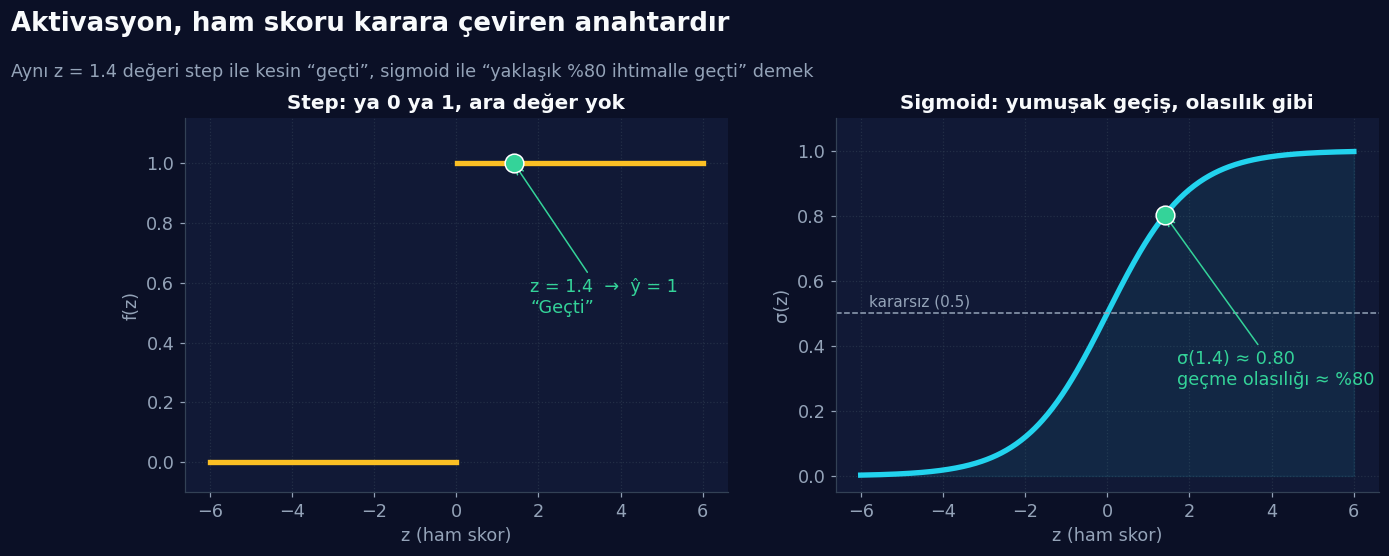

In [9]:
z_ekseni = np.linspace(-6, 6, 400)
fig, eksenler = plt.subplots(1, 2, figsize=(14, 5.0))

ax = eksenler[0]
ax.plot(z_ekseni[z_ekseni <= 0], step(z_ekseni[z_ekseni <= 0]), color=RENK['amber'], lw=3.5)
ax.plot(z_ekseni[z_ekseni > 0], step(z_ekseni[z_ekseni > 0]), color=RENK['amber'], lw=3.5)
ax.scatter([z_takip], [1], s=150, color=RENK['yesil'], edgecolor='white', zorder=5)
ax.annotate('z = 1.4  →  ŷ = 1\n“Geçti”', (z_takip, 1), xytext=(1.8, 0.5), color=RENK['yesil'], fontsize=11.5,
            arrowprops=dict(arrowstyle='->', color=RENK['yesil']))
ax.set_title('Step: ya 0 ya 1, ara değer yok'); ax.set_xlabel('z (ham skor)'); ax.set_ylabel('f(z)')
ax.set_ylim(-0.1, 1.15)

ax = eksenler[1]
ax.plot(z_ekseni, sigmoid(z_ekseni), color=RENK['cam'], lw=3.5)
ax.fill_between(z_ekseni, 0, sigmoid(z_ekseni), color=RENK['cam'], alpha=0.08)
ax.scatter([z_takip], [sigmoid(z_takip)], s=150, color=RENK['yesil'], edgecolor='white', zorder=5)
ax.annotate(f'σ(1.4) ≈ {sigmoid(z_takip):.2f}\ngeçme olasılığı ≈ %{sigmoid(z_takip) * 100:.0f}', (z_takip, sigmoid(z_takip)),
            xytext=(1.7, 0.28), color=RENK['yesil'], fontsize=11.5, arrowprops=dict(arrowstyle='->', color=RENK['yesil']))
ax.axhline(0.5, color=RENK['soluk'], lw=1, ls='--'); ax.text(-5.8, 0.52, 'kararsız (0.5)', color=RENK['soluk'], fontsize=10)
ax.set_title('Sigmoid: yumuşak geçiş, olasılık gibi'); ax.set_xlabel('z (ham skor)'); ax.set_ylabel('σ(z)')
ax.set_ylim(-0.05, 1.1)

baslik(fig, 'Aktivasyon, ham skoru karara çeviren anahtardır', 'Aynı z = 1.4 değeri step ile kesin “geçti”, sigmoid ile “yaklaşık %80 ihtimalle geçti” demek', ust=0.79)
kaydet(fig, '05_step_ve_sigmoid')

### 📋 Üç Öğrencinin Tam Karar Tablosu

Kaynaktaki ağırlıklarla (`w₁=0.04, w₂=0.6, b=−5`) üç öğrencinin ham skorlarını, sigmoid olasılıklarını ve step kararlarını yan yana görelim:

In [10]:
w = np.array([0.04, 0.6]); b = -5.0
z_hepsi = X @ w + b

karar_tablosu = pd.DataFrame({
    'IQ': X[:, 0].astype(int), 'Çalışma': X[:, 1].astype(int),
    'z (ham skor)': z_hepsi, 'σ(z) olasılık': sigmoid(z_hepsi),
    'Step kararı': step(z_hepsi), 'Gerçek y': y,
}, index=['A', 'B', 'C'])
karar_tablosu['Doğru mu?'] = np.where(karar_tablosu['Step kararı'] == karar_tablosu['Gerçek y'], '✅', '❌')
display(karar_tablosu.round(3))

,IQ,Çalışma,z (ham skor),σ(z) olasılık,Step kararı,Gerçek y,Doğru mu?
A,95,3,0.6,0.646,1,0,❌
B,110,4,1.8,0.858,1,1,✅
C,100,5,2.0,0.881,1,1,✅


<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="dikkat">

**Aktivasyon olmasaydı ne olurdu?** Çıktı doğrudan `ŷ = z = 1.4` olurdu. Bu değer “geçti mi kaldı mı?” sorusuna cevap vermez. `z = 7.3` çıksa “%730 ihtimalle geçti” mi diyeceğiz? Aktivasyon fonksiyonu, perceptron’un **karar mekanizmasıdır.**

</td></tr></table>

### ➕ Ek örnek (kaynakta yok): Aktivasyon Olmazsa Katman Eklemenin Anlamı Kalmaz

Bu bilgi bir sonraki bölümlere de ışık tutacağı için kısaca gösterelim: aktivasyon (doğrusal olmayan bir fonksiyon) olmadan **art arda kaç katman koyarsan koy**, hepsi matematiksel olarak **tek bir katmana** indirgenir. Küçük bir deneyle görelim:

In [11]:
rng = np.random.default_rng(0)
W_a = rng.normal(size=(3, 4))     # 1. katman: 3 girdi → 4 nöron
W_b = rng.normal(size=(4, 1))     # 2. katman: 4 nöron → 1 çıktı
x_ornek = rng.normal(size=3)

iki_katman = (x_ornek @ W_a) @ W_b      # aktivasyonsuz 2 katman
tek_katman = x_ornek @ (W_a @ W_b)      # aynı işi yapan TEK katman
print('İki katman sonucu :', iki_katman)
print('Tek katman sonucu :', tek_katman)
print('Aynı mı?          :', np.allclose(iki_katman, tek_katman))

İki katman sonucu : [2.0784]
Tek katman sonucu : [2.0784]
Aynı mı?          : True


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**Aktivasyon olmadan derinlik boşa gider:** 10 katman da koysan, tek bir doğrusal katmandan farksız kalırsın. Sigmoid, ReLU gibi **doğrusal olmayan** aktivasyonlar, ağa karmaşık şekilleri öğrenme gücü verir.

</td></tr></table>

<a id="b6"></a>

<p align="center"><img src="assets/bolum_06.svg" width="100%" alt="Bölüm 6 — Doğrusal Sınır"></p>

### 🎭 Benzetme: Masaya Bir Cetvel Koymak

Masaya karışık dizilmiş **yeşil ve kırmızı bilyeleri** düşün. **Tek bir cetvel** koyup “şu tarafı yeşiller, bu tarafı kırmızılar” diyebiliyorsan, problem **doğrusal olarak ayrılabilir**dir. Perceptron’un yaptığı da tam olarak budur: tek bir doğru (çok boyutta *hiper-düzlem*) çizer.

<table><tr>
<td width="50%" valign="top"><h4>✅ Avantajlar</h4><ul><li>Basit ve sezgisel yapı</li><li>Hızlı öğrenme</li><li>Doğrusal problemler için yeterli</li></ul></td>
<td width="50%" valign="top"><h4>⚠️ Sınırlamalar</h4><ul><li>Doğrusal olmayan problemleri çözemez</li><li>Karmaşık karar sınırlarını öğrenemez</li></ul></td>
</tr></table>

### 🧪 Deney 1: Ayrılabilir Bir Sınıf (simülasyon verisi)

Gerçek bir sınıfı taklit eden **70 öğrencilik rastgele (simülasyon) veri** üretelim. Üretim kuralı bizim: *“0.05·IQ + 0.7·saat − 8.2 > 0 ise geçer, üstüne biraz rastgelelik”*. Bu veri **bizim ürettiğimiz** bir oyuncak veridir, gerçek öğrenci verisi değildir. Soru: kaynaktaki ağırlıklar (`0.04, 0.6, −5`) bu sınıfı ne kadar iyi ayırıyor?

In [12]:
rng = np.random.default_rng(42)
n_ogrenci = 70
iq_sim = rng.normal(100, 10, n_ogrenci)
saat_sim = rng.uniform(0.5, 8, n_ogrenci)
skor_sim = 0.05 * iq_sim + 0.7 * saat_sim - 8.2 + rng.normal(0, 0.35, n_ogrenci)
y_sim = (skor_sim > 0).astype(int)
X_sim = np.column_stack([iq_sim, saat_sim])

def dogruluk(X_, y_, w_, b_):
    return (step(X_ @ w_ + b_) == y_).mean()

acc_pdf = dogruluk(X_sim, y_sim, np.array([0.04, 0.6]), -5.0)
acc_iyi = dogruluk(X_sim, y_sim, np.array([0.05, 0.7]), -8.2)
print(f'Geçen: {y_sim.sum()}  Kalan: {n_ogrenci - y_sim.sum()}')
print(f'Kaynaktaki örnek ağırlıklarla doğruluk : %{acc_pdf * 100:.0f}')
print(f'Veriye uygun ağırlıklarla doğruluk     : %{acc_iyi * 100:.0f}')

Geçen: 29  Kalan: 41
Kaynaktaki örnek ağırlıklarla doğruluk : %61
Veriye uygun ağırlıklarla doğruluk     : %94


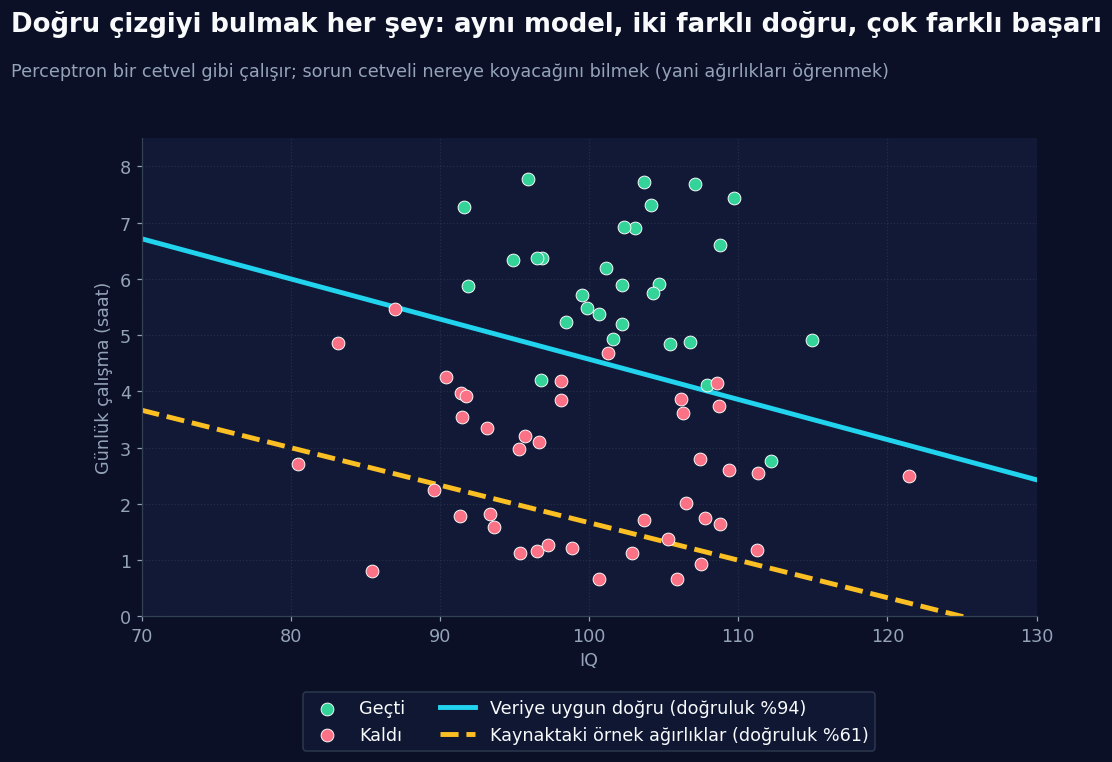

In [13]:
fig, ax = plt.subplots(figsize=(10.5, 6.3))
iq_cizgi = np.linspace(70, 130, 100)
ax.scatter(iq_sim[y_sim == 1], saat_sim[y_sim == 1], s=70, color=RENK['yesil'], edgecolor='white', linewidth=0.6, label='Geçti', zorder=4)
ax.scatter(iq_sim[y_sim == 0], saat_sim[y_sim == 0], s=70, color=RENK['gul'], edgecolor='white', linewidth=0.6, label='Kaldı', zorder=4)
ax.plot(iq_cizgi, sinir_cizgisi(iq_cizgi, 0.05, 0.7, -8.2), color=RENK['cam'], lw=3.2, label=f'Veriye uygun doğru (doğruluk %{acc_iyi * 100:.0f})')
ax.plot(iq_cizgi, sinir_cizgisi(iq_cizgi, 0.04, 0.6, -5.0), color=RENK['amber'], lw=3.2, ls='--', label=f'Kaynaktaki örnek ağırlıklar (doğruluk %{acc_pdf * 100:.0f})')
ax.set_xlim(70, 130); ax.set_ylim(0, 8.5)
ax.set_xlabel('IQ'); ax.set_ylabel('Günlük çalışma (saat)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=True)
baslik(fig, 'Doğru çizgiyi bulmak her şey: aynı model, iki farklı doğru, çok farklı başarı', 'Perceptron bir cetvel gibi çalışır; sorun cetveli nereye koyacağını bilmek (yani ağırlıkları öğrenmek)', ust=0.80)
kaydet(fig, '06_dogrusal_siniflandirma')

### 🧪 Deney 2 (ek örnek, kaynakta yok): Cetvelin Yetmediği Yer, XOR

Dört nokta düşün: `(0,0)` ve `(1,1)` **kırmızı**, `(0,1)` ve `(1,0)` **yeşil** (“ikisi aynıysa 0, farklıysa 1”: **XOR**). Bunları **tek bir doğruyla** ayırabilir misin? Bilgisayara soralım: 50.000 rastgele doğru deneyelim, hangisi en çok noktayı doğru ayırıyor?

50.000 rastgele doğru denendi → ulaşılan en iyi doğruluk: %75  (4 noktadan en fazla 3’ü doğru)


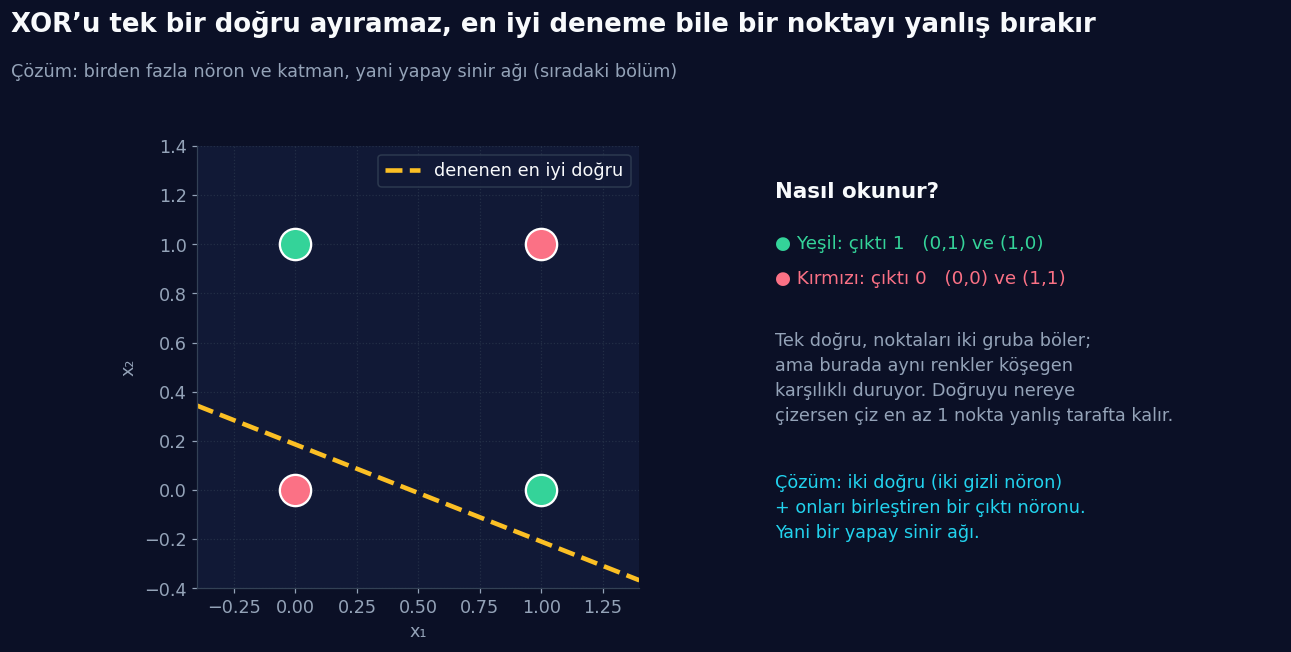

In [14]:
P = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
T = np.array([0, 1, 1, 0])

rng = np.random.default_rng(0)
en_iyi, en_iyi_dogru = 0.0, None
for _ in range(50_000):
    w_r = rng.normal(size=2); b_r = rng.normal() * 1.5
    acc = (step(P @ w_r + b_r) == T).mean()
    if acc > en_iyi:
        en_iyi, en_iyi_dogru = acc, (w_r.copy(), b_r)
print(f'50.000 rastgele doğru denendi → ulaşılan en iyi doğruluk: %{en_iyi * 100:.0f}  (4 noktadan en fazla 3’ü doğru)')

fig, (ax, ax_not) = plt.subplots(1, 2, figsize=(13, 6.0), gridspec_kw={'width_ratios': [1, 1.05]})
for yy_, xx_ in [(0, 0), (1, 1)]:
    ax.scatter(xx_, yy_, s=420, color=RENK['gul'], edgecolor='white', linewidth=1.5, zorder=5)
for yy_, xx_ in [(1, 0), (0, 1)]:
    ax.scatter(xx_, yy_, s=420, color=RENK['yesil'], edgecolor='white', linewidth=1.5, zorder=5)
w_r, b_r = en_iyi_dogru
xs = np.linspace(-0.4, 1.4, 50)
if abs(w_r[1]) > 1e-6:
    ax.plot(xs, -(w_r[0] * xs + b_r) / w_r[1], color=RENK['amber'], lw=3, ls='--', label='denenen en iyi doğru')
ax.set_xlim(-0.4, 1.4); ax.set_ylim(-0.4, 1.4); ax.set_aspect('equal')
ax.set_xlabel('x₁'); ax.set_ylabel('x₂'); ax.legend(loc='upper right')
ax_not.axis('off'); ax_not.grid(False)
ax_not.text(0.02, 0.92, 'Nasıl okunur?', fontsize=14, fontweight='bold', color=RENK['metin'], va='top')
ax_not.text(0.02, 0.80, '● Yeşil: çıktı 1   (0,1) ve (1,0)', fontsize=12, color=RENK['yesil'], va='top')
ax_not.text(0.02, 0.72, '● Kırmızı: çıktı 0   (0,0) ve (1,1)', fontsize=12, color=RENK['gul'], va='top')
ax_not.text(0.02, 0.58, 'Tek doğru, noktaları iki gruba böler;\nama burada aynı renkler köşegen\nkarşılıklı duruyor. Doğruyu nereye\nçizersen çiz en az 1 nokta yanlış tarafta kalır.', fontsize=11.5, color=RENK['soluk'], va='top', linespacing=1.5)
ax_not.text(0.02, 0.26, 'Çözüm: iki doğru (iki gizli nöron)\n+ onları birleştiren bir çıktı nöronu.\nYani bir yapay sinir ağı.', fontsize=11.5, color=RENK['cam'], va='top', linespacing=1.5)
baslik(fig, 'XOR’u tek bir doğru ayıramaz, en iyi deneme bile bir noktayı yanlış bırakır', 'Çözüm: birden fazla nöron ve katman, yani yapay sinir ağı (sıradaki bölüm)', ust=0.78)
kaydet(fig, '06_xor_dogrusal_degil')

<table><tr><td>

<img src="assets/etiket_ybs.svg" height="34" alt="ybs">

**Gerçek iş dünyasında** müşteri kaybı (churn), kredi riski, talep tahmini gibi problemlerin çoğunda sınıflar **doğrusal olarak ayrılmaz**: “genç ve yüksek gelirli” ya da “yaşlı ve düşük gelirli” müşteri riskliyken, diğer iki grup güvenli olabilir (XOR benzeri bir yapı). Tek nöron burada çaresiz kalır; bu yüzden **birden çok nöronu katmanlar halinde** birleştiriyoruz.

</td></tr></table>

<a id="b7"></a>

<p align="center"><img src="assets/bolum_07.svg" width="100%" alt="Bölüm 7 — Çok Katmanlı Ağ (ANN)"></p>

### 🎭 Benzetme: Şirket Hiyerarşisi

Bir tek jüri üyesi (perceptron) basit işleri halleder ama büyük kararlar tek kişiyle verilmez. Şirkette olduğu gibi **katmanlı bir yapı** kurarız:

| Şirkette | Ağda | Ne yapar? |
|:--|:--|:--|
| 📥 Stajyerler (veri toplar) | **Input Layer** (girdi katmanı) | Ham bilgiyi içeri alır |
| 🧑‍💼 Departman müdürü (özetler, yorumlar) | **Hidden Layer** (gizli katman) | Girdilerden “ara özellikler” çıkarır |
| 👔 Genel müdür (nihai karar) | **Output Layer** (çıktı katmanı) | Tahmini üretir (`ŷ`) |

Gerçek hayat problemleri çoğunlukla **doğrusal değildir**, **birden fazla değişkenin birlikte etkisini** içerir ve **karmaşık karar sınırları** gerektirir. Tek nöron yetmediğinde **birden fazla nöron ve katman birlikte çalışır**. Bu yapıya **Artificial Neural Network (ANN)** denir.

### 🏗️ Bu Bölümde Kullanacağımız Mini Ağ

Kaynak doküman, ağın **her sayısını elle hesaplayabilelim** diye kasıtlı olarak çok küçük bir mimari kullanıyor: **3 girdi → 1 gizli nöron → 1 çıktı nöronu.** Bir de örneğimizi **genişletiyoruz**: artık öğrencinin **günlük oyun süresine** (`x₃`) de bakıyoruz.

| Katman | İçeriği | Örnek öğrenci |
|:--|:--|:--|
| **Girdi** | 3 özellik: IQ (`x₁`), çalışma saati (`x₂`), oyun saati (`x₃`) | `x₁ = 95`, `x₂ = 4`, `x₃ = 4` |
| **Gizli** | 1 nöron (`h₁`) | Girdileri tartıp özetler |
| **Çıktı** | 1 nöron (`ŷ`) | Geçme tahmini |
| **Gerçek sonuç** | Etiket | `y = 1` (geçti) |

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="not">

**Gerçek ağlar çok daha büyüktür:** her katmanda yüzlerce nöron, onlarca katman olabilir. Biz öğrenirken **tek gizli nöron** kullanıyoruz çünkü böylece ağın içindeki *her* sayıyı elimizle izleyebiliyoruz. Mantık, ağ büyüse de değişmez.

</td></tr></table>

<a id="b8"></a>

<p align="center"><img src="assets/bolum_08.svg" width="100%" alt="Bölüm 8 — Forward Propagation"></p>

### 🎭 Benzetme: Sipariş Akışı

Bir online sipariş düşün: müşteri siparişi verir → şube hazırlar → merkez onaylar → kargo çıkar. Veri **tek yönde, soldan sağa** ilerler. **Forward propagation (ileri yayılım)** de girdilerin ağ içinde **soldan sağa işlenmesidir.** Her nöronda **aynı iki adım** olur:

1. Girdileri **ağırlıklarla çarpıp topla** (artı bias),
2. Sonucu bir **aktivasyon fonksiyonundan** geçir (burada sigmoid).

Animasyonda mavi noktalar verinin akışıdır; sayılar kaynak dokümandakiyle birebir aynı:

<p align="center"><img src="assets/ann_ileri.svg" width="100%" alt="Animasyon: 3-1-1 ağında ileri yayılım"></p>

### 🔢 Adım Adım Hesap

**Başlangıç değerleri** (kaynakta “örnek amaçlı” seçilmiş):

- Gizli nöron: `w₁ = 0.01`, `w₂ = 0.02`, `w₃ = 0.03`, `b₁ = 0.001`
- Çıktı nöronu: `w₄ = 0.02`, `b₂ = 0.03`

**Gizli katman:** `z₁ = w₁x₁ + w₂x₂ + w₃x₃ + b₁` → sigmoid → `o₁`

**Çıktı katmanı:** `z₂ = o₁·w₄ + b₂` → sigmoid → `ŷ`

In [15]:
# Örnek öğrenci: IQ = 95, çalışma = 4 saat, oyun = 4 saat. Gerçek sonuç: geçti (1)
x_ogr = np.array([95.0, 4.0, 4.0])
y_ogr = 1.0

# Başlangıç parametreleri (kaynaktaki değerler)
P0 = {'w': np.array([0.01, 0.02, 0.03]), 'b1': 0.001, 'w4': 0.02, 'b2': 0.03}

# ── Gizli katman ──
z1 = P0['w'][0] * x_ogr[0] + P0['w'][1] * x_ogr[1] + P0['w'][2] * x_ogr[2] + P0['b1']
o1 = sigmoid(z1)
print(f'Gizli katman  z₁ = (95·0.01) + (4·0.02) + (4·0.03) + 0.001 = {z1:.3f}')
print(f'Aktivasyon    o₁ = σ({z1:.3f}) = {o1:.4f}   ← nöronun “ne kadar aktif” olduğu')

# ── Çıktı katmanı ──
z2 = o1 * P0['w4'] + P0['b2']
yhat = sigmoid(z2)
print(f'Çıktı katmanı z₂ = {o1:.4f}·0.02 + 0.03 = {z2:.5f}')
print(f'Tahmin        ŷ  = σ({z2:.5f}) = {yhat:.3f}')

Gizli katman  z₁ = (95·0.01) + (4·0.02) + (4·0.03) + 0.001 = 1.151
Aktivasyon    o₁ = σ(1.151) = 0.7597   ← nöronun “ne kadar aktif” olduğu
Çıktı katmanı z₂ = 0.7597·0.02 + 0.03 = 0.04519
Tahmin        ŷ  = σ(0.04519) = 0.511


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**Tahmin ≈ 0.511**: ağ “geçti” (1) ile “kaldı” (0) arasında **kararsız**. Çok normal! Ağırlıkları *rastgele-küçük* değerlerle başlattık, ağ henüz hiçbir şey öğrenmedi. Gerçek sonuç `y = 1` olduğuna göre tahmin aslında **yanlış yönde**; hatayı ölçüp düzeltme sırası geldi.

*Küçük not:* Kaynak `o₁ ≈ 0.759` ve `z₂ = 0.04518` yazıyor; kod tam değeri kullandığı için `o₁ = 0.7597`, `z₂ = 0.04519` çıkıyor. Fark yalnızca yuvarlamadan gelir; `ŷ ≈ 0.511` her iki yolda da aynıdır.

</td></tr></table>

In [16]:
def ileri(x, p):
    """Ağın ileri geçişi: girdiyi alır, ara değerleri ve tahmini döndürür."""
    z1 = np.dot(p['w'], x) + p['b1']      # gizli nöron: ağırlıklı toplam
    o1 = sigmoid(z1)                       # gizli nöron: aktivasyon
    z2 = o1 * p['w4'] + p['b2']            # çıktı nöronu: ağırlıklı toplam
    yhat = sigmoid(z2)                     # çıktı nöronu: aktivasyon = tahmin
    return {'z1': z1, 'o1': o1, 'z2': z2, 'yhat': yhat}

c = ileri(x_ogr, P0)
print({k: round(float(v), 5) for k, v in c.items()})

# Kaynaktaki sayılarla uyuşuyor mu? (kendi kodumuzu doğruluyoruz)
assert abs(c['z1'] - 1.151) < 1e-9
assert abs(c['o1'] - 0.759) < 1e-3
assert abs(c['z2'] - 0.04518) < 1e-3
assert abs(c['yhat'] - 0.511) < 1e-3
print('✅ Fonksiyonumuz kaynaktaki tüm değerleri yeniden üretti.')

{'z1': 1.151, 'o1': 0.75969, 'z2': 0.04519, 'yhat': 0.5113}
✅ Fonksiyonumuz kaynaktaki tüm değerleri yeniden üretti.


### 🎲 Ağırlıklar Neden Rastgele Başlatılır?

Eğitime başlarken ağ **doğru ağırlıkları bilemez.** Bu yüzden ağırlıklar **küçük rastgele değerlerle** başlatılır. Peki hepsini **sıfırdan** (ya da hepsini aynı değerden) başlatsak?

> 🎭 **Benzetme:** Bir şirkette 10 çalışana **birebir aynı talimatı, aynı bilgiyle** verirsen hepsi **aynı raporu** yazar. 10 çalışan tutmanın anlamı kalmaz; tek çalışan yeterliydi.

Aynı şey ağda da olur: tüm nöronlar **aynı şeyi öğrenir**, öğrenme gerçekleşmez. Bu yüzden başlangıç ağırlıkları **küçük, rastgele ve simetriyi bozacak** şekilde seçilir. Önce *ileri* yönde görelim (eğitim kısmını Bölüm 11’de göreceğiz):

In [17]:
# 2 gizli nöronlu mini ağ: hepsi aynı değerle başlatılırsa iki nöron birbirinin kopyası olur
W_ayni = np.full((2, 3), 0.01)
print('Aynı başlatma     → iki gizli nöronun çıktısı:', sigmoid(W_ayni @ x_ogr))

rng = np.random.default_rng(1)
W_rastgele = rng.normal(0, 0.02, size=(2, 3))
print('Rastgele başlatma → iki gizli nöronun çıktısı:', sigmoid(W_rastgele @ x_ogr))

Aynı başlatma     → iki gizli nöronun çıktısı: [0.7369 0.7369]
Rastgele başlatma → iki gizli nöronun çıktısı: [0.6789 0.0857]


<a id="b9"></a>

<p align="center"><img src="assets/bolum_09.svg" width="100%" alt="Bölüm 9 — Loss: Ne Kadar Yanlışız?"></p>

### 🎭 Benzetme: Dart Atışı

Dart atarken hedefin **tam ortasına** olan uzaklık, atışının *hata puanıdır*. Sinir ağında bu uzaklığa **loss (kayıp, hata)** diyoruz. Ağın tahmini `ŷ`, gerçek sonuç `y` ise en basit loss:

> **L = (y − ŷ)²**

Bunu şöyle okuyabilirsin: *“Tahmin ile gerçek arasındaki fark büyüdükçe, loss büyür.”* Eğitimin hedefi zaten budur: **loss’u küçültmek** (`min L`).

**Neden kare?** (1) Fark negatif de olsa pozitif de olsa hata pozitif sayılır, (2) büyük hatalar daha çok cezalandırılır.

In [18]:
def kayip(y, yhat):
    """Kareli hata: L = (y − ŷ)²"""
    return (y - yhat) ** 2

L0 = kayip(y_ogr, c['yhat'])
print(f'Gerçek y = {y_ogr:.0f},  tahmin ŷ = {c["yhat"]:.3f}  →  L = (1 − {c["yhat"]:.3f})² = {L0:.3f}')

print()
print('Farklı tahminler için hata nasıl değişiyor? (gerçek y = 1)')
for tahmin in [0.0, 0.25, c['yhat'], 0.75, 0.9, 1.0]:
    print(f'  ŷ = {tahmin:.3f}  →  L = {kayip(1.0, tahmin):.3f}')

Gerçek y = 1,  tahmin ŷ = 0.511  →  L = (1 − 0.511)² = 0.239

Farklı tahminler için hata nasıl değişiyor? (gerçek y = 1)
  ŷ = 0.000  →  L = 1.000
  ŷ = 0.250  →  L = 0.562
  ŷ = 0.511  →  L = 0.239
  ŷ = 0.750  →  L = 0.062
  ŷ = 0.900  →  L = 0.010
  ŷ = 1.000  →  L = 0.000


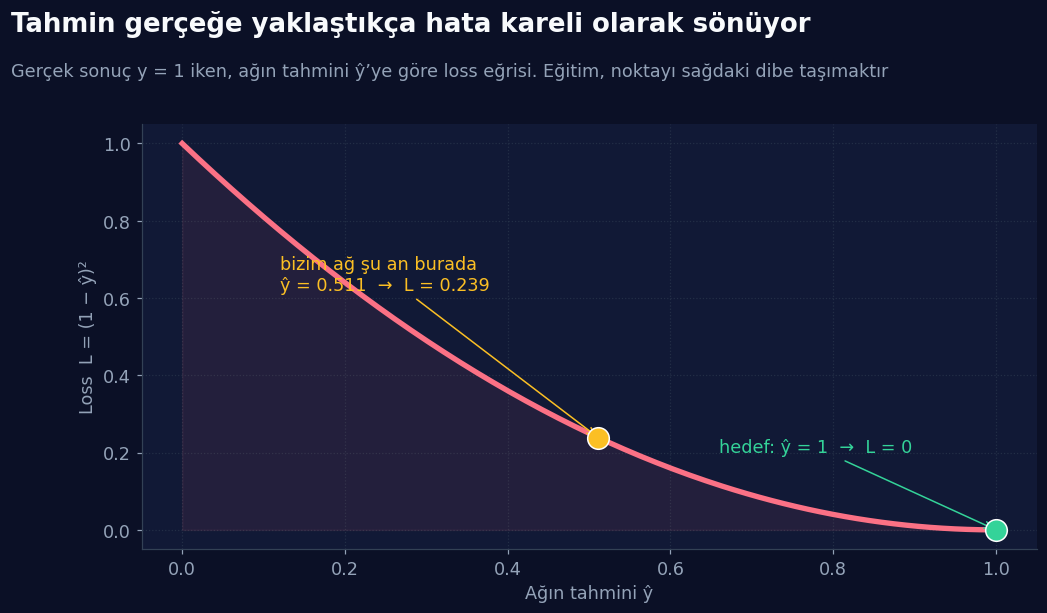

In [19]:
yh = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(10.5, 5.6))
ax.plot(yh, kayip(1.0, yh), color=RENK['gul'], lw=3.5)
ax.fill_between(yh, 0, kayip(1.0, yh), color=RENK['gul'], alpha=0.08)
ax.scatter([c['yhat']], [L0], s=200, color=RENK['amber'], edgecolor='white', zorder=5)
ax.annotate(f'bizim ağ şu an burada\nŷ = {c["yhat"]:.3f}  →  L = {L0:.3f}', (c['yhat'], L0), xytext=(0.12, 0.62),
            color=RENK['amber'], fontsize=11.5, arrowprops=dict(arrowstyle='->', color=RENK['amber']))
ax.scatter([1.0], [0.0], s=200, color=RENK['yesil'], edgecolor='white', zorder=5)
ax.annotate('hedef: ŷ = 1  →  L = 0', (1.0, 0.0), xytext=(0.66, 0.2), color=RENK['yesil'], fontsize=11.5,
            arrowprops=dict(arrowstyle='->', color=RENK['yesil']))
ax.set_xlabel('Ağın tahmini ŷ'); ax.set_ylabel('Loss  L = (1 − ŷ)²')
baslik(fig, 'Tahmin gerçeğe yaklaştıkça hata kareli olarak sönüyor', 'Gerçek sonuç y = 1 iken, ağın tahmini ŷ’ye göre loss eğrisi. Eğitim, noktayı sağdaki dibe taşımaktır', ust=0.80)
kaydet(fig, '09_loss_egrisi')

<table><tr><td>

<img src="assets/etiket_ybs.svg" height="34" alt="ybs">

**İşletme dilinde loss = maliyet.** Talep tahmininde “10 sipariş bekledik, 14 geldi” farkı stok/mağduriyet maliyetidir. Modeli eğitmek, bu maliyeti en aza indiren ayarı bulmaktır. (Kaynakta sıradaki derslerde farklı loss türleri, örneğin **MSE ve Cross-Entropy**, ayrıca işlenecek.)

</td></tr></table>

<a id="b10"></a>

<p align="center"><img src="assets/bolum_10.svg" width="100%" alt="Bölüm 10 — Gradient Descent"></p>

### 🎭 Benzetme: Sisli Dağda Gözü Kapalı Vadiye İnmek

Sisli bir dağdasın, görüş yok. En alçak noktaya (vadiye) inmek istiyorsun. Ne yaparsın? **Ayağının altındaki yamacın eğimini hissedersin**: eğim aşağıya doğruysa o yöne bir adım atarsın, sonra yine hissedersin, yine adım atarsın… **Gradient descent (gradyan inişi)** tam olarak budur.

<table><tr>
<td width="50%" valign="top"><h4>📐 Türev = Yön</h4>Loss’u tek bir ağırlığa göre çizdiğini hayal et. <b>Türev</b> (∂L/∂w), bulunduğun noktadaki eğimi söyler: pozitif mi negatif mi? Yani <i>“sağa gidersem aşağı mı inerim, sola gidersem mi?”</i> sorusunun matematiksel cevabıdır.</td>
<td width="50%" valign="top"><h4>👣 Learning Rate = Adım Boyu</h4><b>η</b> (eta) adım büyüklüğüdür. Çok küçük: güvenli ama <i>yavaş</i>. Çok büyük: hızlı görünür ama <i>hedefi ıskalar</i> (vadinin karşı yamacına zıplarsın).</td>
</tr></table>

> **w_yeni = w_eski − η · ∂L/∂w**  *(Loss’u artıran yönden uzaklaş, loss’u azaltan yöne yaklaş.)*

<p align="center"><img src="assets/vadiye_inis.svg" width="100%" alt="Animasyon: gradient descent ile vadiye iniş"></p>

### 📐 Türev Gerçekten “Yön” Söylüyor mu?

Basit bir oyuncak loss alalım: **L(w) = (w − 2)²**. En alçak nokta `w = 2`’de. Türevi `2(w − 2)`. İki farklı noktada eğime bakalım:

In [20]:
def L_oyuncak(w):
    return (w - 2) ** 2

def dL_oyuncak(w):
    return 2 * (w - 2)

for w_nokta in [-1.0, 5.0]:
    egim = dL_oyuncak(w_nokta)
    yon = 'SAĞA (w’yi artır)' if egim < 0 else 'SOLA (w’yi azalt)'
    print(f'w = {w_nokta:>4}:  eğim (türev) = {egim:>5.1f}  → gitmeli: {yon}')

w = -1.0:  eğim (türev) =  -6.0  → gitmeli: SAĞA (w’yi artır)
w =  5.0:  eğim (türev) =   6.0  → gitmeli: SOLA (w’yi azalt)


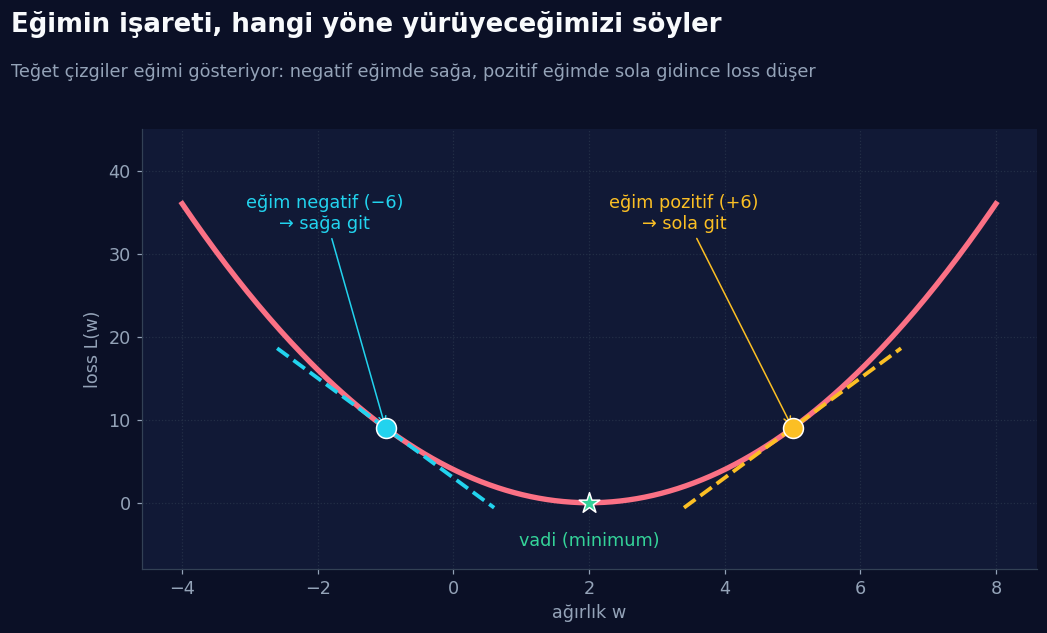

In [21]:
w_cizgi = np.linspace(-4, 8, 300)
fig, ax = plt.subplots(figsize=(10.5, 5.8))
ax.plot(w_cizgi, L_oyuncak(w_cizgi), color=RENK['gul'], lw=3.5)
for w_nokta, renk, yon_yazi, dx in [(-1.0, RENK['cam'], 'eğim negatif (−6)\n→ sağa git', -0.9), (5.0, RENK['amber'], 'eğim pozitif (+6)\n→ sola git', -1.6)]:
    egim = dL_oyuncak(w_nokta); y0 = L_oyuncak(w_nokta)
    xs = np.linspace(w_nokta - 1.6, w_nokta + 1.6, 10)
    ax.plot(xs, y0 + egim * (xs - w_nokta), color=renk, lw=2.5, ls='--')
    ax.scatter([w_nokta], [y0], s=170, color=renk, edgecolor='white', zorder=5)
    ax.annotate(yon_yazi, (w_nokta, y0), xytext=(w_nokta + dx, 33), color=renk, fontsize=11.5, ha='center', arrowprops=dict(arrowstyle='->', color=renk))
ax.scatter([2], [0], s=200, marker='*', color=RENK['yesil'], zorder=6, edgecolor='white')
ax.text(2, -5.2, 'vadi (minimum)', color=RENK['yesil'], fontsize=11.5, ha='center')
ax.set_xlabel('ağırlık w'); ax.set_ylabel('loss L(w)'); ax.set_ylim(-8, 45)
baslik(fig, 'Eğimin işareti, hangi yöne yürüyeceğimizi söyler', 'Teğet çizgiler eğimi gösteriyor: negatif eğimde sağa, pozitif eğimde sola gidince loss düşer', ust=0.80)
kaydet(fig, '10_turev_yon_gosterir')

### 👣 Learning Rate Deneyi: Üç Farklı Adım Boyu

Aynı vadiye, **aynı başlangıç noktasından** (`w = −1`) üç farklı adım boyuyla inelim: **çok küçük** (0.05), **uygun** (0.4), **çok büyük** (1.1). Her adımda `w_yeni = w_eski − η · türev` uyguluyoruz.

In [22]:
def gd_yolu(w0, eta, adim):
    """Gradient descent: her adımda w_yeni = w_eski − η · türev"""
    yol = [w0]
    for _ in range(adim):
        yol.append(yol[-1] - eta * dL_oyuncak(yol[-1]))
    return np.array(yol)

ETALAR = [(0.05, 'Çok küçük  η = 0.05', RENK['cam']),
          (0.40, 'Uygun  η = 0.4', RENK['yesil']),
          (1.10, 'Çok büyük  η = 1.1', RENK['gul'])]

for eta, ad, _ in ETALAR:
    yol = gd_yolu(-1.0, eta, 8)
    print(f'{ad:<22} w değerleri: {np.round(yol, 2)}')
    print(f'{"":<22} son loss    : {L_oyuncak(yol[-1]):.4f}')

Çok küçük  η = 0.05    w değerleri: [-1.   -0.7  -0.43 -0.19  0.03  0.23  0.41  0.57  0.71]
                       son loss    : 1.6677
Uygun  η = 0.4         w değerleri: [-1.    1.4   1.88  1.98  2.    2.    2.    2.    2.  ]
                       son loss    : 0.0000
Çok büyük  η = 1.1     w değerleri: [ -1.     5.6   -2.32   7.18  -4.22   9.46  -6.96  12.75 -10.9 ]
                       son loss    : 166.3958


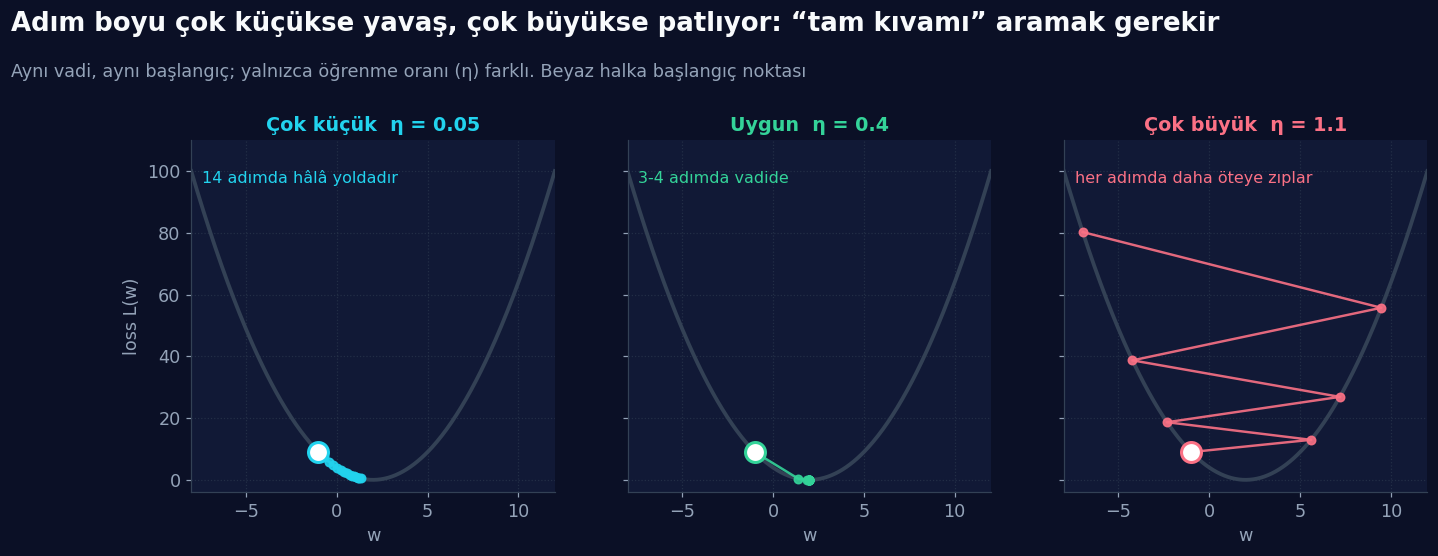

In [23]:
YOLLAR = [gd_yolu(-1.0, eta, 14) for eta, _, _ in ETALAR]
w_cizgi = np.linspace(-8, 12, 300)
fig, eksenler = plt.subplots(1, 3, figsize=(14.5, 5.0), sharey=True)
for ax, yol, (eta, ad, renk) in zip(eksenler, YOLLAR, ETALAR):
    ax.plot(w_cizgi, L_oyuncak(w_cizgi), color=RENK['izgara'], lw=2.5)
    gorunen = yol[(yol > -8) & (yol < 12)]
    ax.plot(gorunen, L_oyuncak(gorunen), '-o', color=renk, lw=1.6, ms=5.5, alpha=0.9)
    ax.scatter([yol[0]], [L_oyuncak(yol[0])], s=170, color='white', zorder=6, edgecolor=renk, linewidth=2)
    ax.set_title(ad, color=renk, fontsize=12.5); ax.set_xlabel('w'); ax.set_xlim(-8, 12); ax.set_ylim(-4, 110)
eksenler[0].set_ylabel('loss L(w)')
eksenler[0].text(-7.4, 96, '14 adımda hâlâ yoldadır', color=RENK['cam'], fontsize=10.5)
eksenler[1].text(-7.4, 96, '3-4 adımda vadide', color=RENK['yesil'], fontsize=10.5)
eksenler[2].text(-7.4, 96, 'her adımda daha öteye zıplar', color=RENK['gul'], fontsize=10.5)
baslik(fig, 'Adım boyu çok küçükse yavaş, çok büyükse patlıyor: “tam kıvamı” aramak gerekir', 'Aynı vadi, aynı başlangıç; yalnızca öğrenme oranı (η) farklı. Beyaz halka başlangıç noktası', ust=0.75)
kaydet(fig, '10_ogrenme_orani_deneyi')

### 🎬 Aynısı, Hareketli: Gradient Descent Animasyonu

Aşağıdaki animasyon az önceki üç deneyi **adım adım** oynatıyor (adım 0’dan 14’e). Küçük η’da topun nasıl sürünerek indiğine, büyük η’da nasıl vadinin iki yamacı arasında gittikçe **daha uzağa** zıpladığına bak:

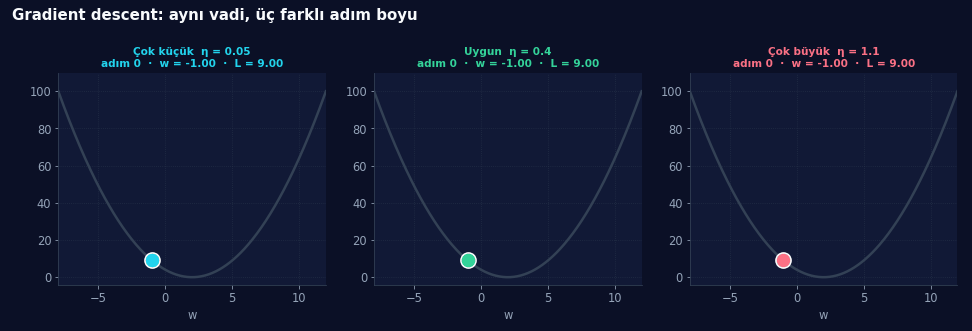

Animasyon kaydedildi: outputs\figures\10_gradient_descent.gif  (161 KB)


In [24]:
GIF_YOLU = FIG_DIR / '10_gradient_descent.gif'
fig, eksenler = plt.subplots(1, 3, figsize=(13.5, 4.6))
fig.text(0.012, 0.975, 'Gradient descent: aynı vadi, üç farklı adım boyu', fontsize=15, fontweight='bold', va='top')
fig.subplots_adjust(top=0.78, bottom=0.14, left=0.06, right=0.985, wspace=0.18)

def kare(t):
    for ax, yol, (eta, ad, renk) in zip(eksenler, YOLLAR, ETALAR):
        ax.clear()
        ax.plot(w_cizgi, L_oyuncak(w_cizgi), color=RENK['izgara'], lw=2.5)
        gecmis = yol[:t + 1]
        gorunen = gecmis[(gecmis > -8) & (gecmis < 12)]
        ax.plot(gorunen, L_oyuncak(gorunen), '-o', color=renk, lw=1.4, ms=5, alpha=0.75)
        if -8 < yol[t] < 12:
            ax.scatter([yol[t]], [L_oyuncak(yol[t])], s=230, color=renk, edgecolor='white', linewidth=1.5, zorder=6)
        ax.set_xlim(-8, 12); ax.set_ylim(-4, 110)
        ax.set_title(f'{ad}\nadım {t}  ·  w = {yol[t]:.2f}  ·  L = {L_oyuncak(yol[t]):.2f}', fontsize=10.5, color=renk)
        ax.set_xlabel('w')

anim = FuncAnimation(fig, kare, frames=15, interval=450)
with mpl.rc_context({'savefig.bbox': 'standard'}):
    anim.save(GIF_YOLU, writer=PillowWriter(fps=2.2), dpi=72)
plt.close(fig)
display(Image(filename=str(GIF_YOLU)))
print(f'Animasyon kaydedildi: {GIF_YOLU}  ({GIF_YOLU.stat().st_size / 1024:.0f} KB)')

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="sonuc">

**Özet:** Türev bize **yönü**, learning rate **adım büyüklüğünü** verir. Gerçek ağlarda binlerce ağırlık vardır ama **mantık aynı**: her ağırlık için “loss’u azaltan yön”ü bul, o yöne küçük bir adım at, tekrarla. Geriye tek soru kalıyor: *ağın içindeki bir ağırlık için türevi nasıl hesaplarız?* Cevap: **backpropagation + zincir kuralı.**

</td></tr></table>

<a id="b11"></a>

<p align="center"><img src="assets/bolum_11.svg" width="100%" alt="Bölüm 11 — Backpropagation"></p>

### 🎭 Benzetme: Müşteri İadesi ve Üretim Hattı

Bir fabrikada müşteri **kusurlu ürünü iade etti.** Soru: *hatayı hangi istasyon yaptı, ne kadar sorumlu?* Müşteriden başlayıp **hattı geriye doğru** takip edersin: paketleme → montaj → ham madde. **Backpropagation (geri yayılım)** de aynıdır:

- **Forward propagation:** veriyi soldan sağa akıtır, `ŷ` üretir.
- **Backpropagation:** loss’tan başlayıp **sağdan sola** giderek *“bu hataya hangi ağırlık ne kadar sebep oldu?”* sorusunu sayısallaştırır.

Backpropagation sayesinde ağırlıkları rastgele oynatmak yerine **hedefli güncelleriz** ve derin ağları pratik biçimde eğitebiliriz.

### ⛓️ Zincir Kuralı (Chain Rule): “Hata Bu Ağırlığa Nasıl Bağlanıyor?”

Burası genelde kafa karıştırır: loss’u ağırlığa göre türevleyeceğiz ama **loss’un formülünde `w` doğrudan görünmüyor.** Ana fikir: aralarında bir **zincir** var:

> **w → z → ŷ → L** (ağırlık değişirse `z` değişir, `z` değişirse `ŷ` değişir, `ŷ` değişirse `L` değişir.)

Yani `L`, `w`’ye **dolaylı** bağlıdır: `L = L(ŷ(z(w)))`. Zincir kuralı, bu halkaların etkisini **çarparak** birleştirir:

> **∂L/∂w = ∂L/∂ŷ · ∂ŷ/∂z · ∂z/∂w**

<p align="center"><img src="assets/zincir_kurali.svg" width="100%" alt="Animasyon: zincir kuralı, hata L’den w’ye halka halka ulaşır"></p>

### ⚙️ Zincir Kuralını Dişli Kutusuyla Düşün

Üç dişli yan yana: ilki ikinciyi, ikinci üçüncüyü döndürüyor. Her dişli çifti bir **çevirme oranına** sahip (×2, ×½, ×3). **Son dişlinin toplam dönüşü, oranların çarpımıdır:** `2 × ½ × 3 = 3`. Zincir kuralı da böyle: toplam etki = halkaların tek tek etkilerinin çarpımı.

<p align="center"><img src="assets/dislier.svg" width="100%" alt="Animasyon: dişli kutusu benzetmesiyle zincir kuralı"></p>

### 🧮 Kendi Ağımızda Zincir Kuralı

Ağımızın zinciri: `z₁ = w₁x₁ + w₂x₂ + w₃x₃ + b₁` → `o₁ = σ(z₁)` → `z₂ = o₁·w₄ + b₂` → `ŷ = σ(z₂)` → `L = (y − ŷ)²`.

**Çıktı katmanındaki ağırlık (`w₄`) daha “direkt” etkilidir; zincir kısadır (3 halka):**

> ∂L/∂w₄ = ∂L/∂ŷ · ∂ŷ/∂z₂ · ∂z₂/∂w₄

**Gizli katmandaki ağırlık (`w₁`) için zincir uzar (4 halka)**, çünkü `w₁` önce gizli nöronu, o da çıktı katmanını, en son loss’u etkiler:

> ∂L/∂w₁ = ∂L/∂ŷ · ∂ŷ/∂o₁ · ∂o₁/∂z₁ · ∂z₁/∂w₁

Korkulacak bir şey yok: **hata, ağırlığa ulaşana kadar kaç adım geçiyorsa türevde o kadar çarpan olur.** Her çarpanın formülü basit:

| Çarpan | Formül | Anlamı |
|:--|:--|:--|
| `∂L/∂ŷ` | `−2(y − ŷ)` | Tahmin değişirse loss ne kadar değişir? |
| `∂ŷ/∂z₂` | `ŷ(1 − ŷ)` | Sigmoid’in türevi |
| `∂z₂/∂w₄` | `o₁` | `w₄`’ün çarpıldığı girdi |
| `∂ŷ/∂o₁` | `ŷ(1 − ŷ)·w₄` | Gizli çıktı değişirse tahmin ne kadar değişir? |
| `∂o₁/∂z₁` | `o₁(1 − o₁)` | Sigmoid’in türevi (gizli katman) |
| `∂z₁/∂w₁` | `x₁` | `w₁`’in çarpıldığı girdi |

In [25]:
# Önceki bölümdeki ileri geçiş değerleri
o1, yhat = c['o1'], c['yhat']
w4 = P0['w4']

print('── Çıktı katmanı ağırlığı w₄ (3 halkalı zincir) ──')
dL_dyhat   = -2 * (y_ogr - yhat)        # ∂L/∂ŷ
dyhat_dz2  = yhat * (1 - yhat)          # ∂ŷ/∂z₂  (sigmoid türevi)
dz2_dw4    = o1                          # ∂z₂/∂w₄
dL_dw4 = dL_dyhat * dyhat_dz2 * dz2_dw4
print(f'∂L/∂ŷ   = −2(1 − {yhat:.3f}) = {dL_dyhat:.4f}')
print(f'∂ŷ/∂z₂  = {yhat:.3f}·(1 − {yhat:.3f}) = {dyhat_dz2:.4f}')
print(f'∂z₂/∂w₄ = o₁ = {dz2_dw4:.4f}')
print(f'→ ∂L/∂w₄ = {dL_dyhat:.4f} × {dyhat_dz2:.4f} × {dz2_dw4:.4f} = {dL_dw4:.4f}')

print()
print('── Gizli katman ağırlığı w₁ (4 halkalı zincir) ──')
dyhat_do1 = yhat * (1 - yhat) * w4      # ∂ŷ/∂o₁
do1_dz1   = o1 * (1 - o1)               # ∂o₁/∂z₁ (sigmoid türevi)
dz1_dw1   = x_ogr[0]                    # ∂z₁/∂w₁ = x₁ = 95
dL_dw1 = dL_dyhat * dyhat_do1 * do1_dz1 * dz1_dw1
print(f'∂L/∂ŷ   = {dL_dyhat:.4f}')
print(f'∂ŷ/∂o₁  = {dyhat_do1:.5f}')
print(f'∂o₁/∂z₁ = {do1_dz1:.4f}')
print(f'∂z₁/∂w₁ = x₁ = {dz1_dw1:.0f}')
print(f'→ ∂L/∂w₁ = {dL_dyhat:.4f} × {dyhat_do1:.5f} × {do1_dz1:.4f} × {dz1_dw1:.0f} = {dL_dw1:.4f}')

── Çıktı katmanı ağırlığı w₄ (3 halkalı zincir) ──
∂L/∂ŷ   = −2(1 − 0.511) = -0.9774
∂ŷ/∂z₂  = 0.511·(1 − 0.511) = 0.2499
∂z₂/∂w₄ = o₁ = 0.7597
→ ∂L/∂w₄ = -0.9774 × 0.2499 × 0.7597 = -0.1855

── Gizli katman ağırlığı w₁ (4 halkalı zincir) ──
∂L/∂ŷ   = -0.9774
∂ŷ/∂o₁  = 0.00500
∂o₁/∂z₁ = 0.1826
∂z₁/∂w₁ = x₁ = 95
→ ∂L/∂w₁ = -0.9774 × 0.00500 × 0.1826 × 95 = -0.0847


İki gradyan da **negatif** çıktı. Hatırla: türev negatifse **ağırlığı artırmalıyız** (loss’u azaltmak için sağa gitmek). Bu da mantıklı: gerçek sonuç `y = 1` ama tahmin `0.511`, yani ağ tahminini yukarı çekmek istiyor. Aşağıdaki animasyonda hatanın **sağdan sola** akışı ve her ağırlığın payı görülüyor:

<p align="center"><img src="assets/ann_geri.svg" width="100%" alt="Animasyon: geri yayılım, hata sağdan sola akar"></p>

In [26]:
def geri(x, y, p, c):
    """Geri yayılım: her parametre için ∂L/∂(parametre) hesaplar."""
    dL_dyhat = -2 * (y - c['yhat'])
    dz2 = dL_dyhat * c['yhat'] * (1 - c['yhat'])        # ∂L/∂z₂ (çıktı nöronuna gelen hata)
    g_w4 = dz2 * c['o1']
    g_b2 = dz2
    dz1 = dz2 * p['w4'] * c['o1'] * (1 - c['o1'])       # ∂L/∂z₁ (hata gizli nörona ulaştı)
    g_w = dz1 * x                                        # w₁, w₂, w₃ için aynı hata, girdiyle çarpılır
    g_b1 = dz1
    return {'w': g_w, 'b1': g_b1, 'w4': g_w4, 'b2': g_b2}

g = geri(x_ogr, y_ogr, P0, c)
print('∂L/∂w₁, w₂, w₃ :', np.round(g['w'], 4))
print('∂L/∂b₁         :', round(float(g['b1']), 5))
print('∂L/∂w₄         :', round(float(g['w4']), 4))
print('∂L/∂b₂         :', round(float(g['b2']), 4))

∂L/∂w₁, w₂, w₃ : [-0.0847 -0.0036 -0.0036]
∂L/∂b₁         : -0.00089
∂L/∂w₄         : -0.1855
∂L/∂b₂         : -0.2442


### 🔍 Güven Testi: Elle Çıkardığımız Türevler Doğru mu?

Kendi türev formüllerimize körü körüne güvenmeyelim. Bir türevi **sayısal olarak** da hesaplayabiliriz: parametreyi çok az (`h = 10⁻⁶`) artırıp azaltarak loss’un nasıl değiştiğine bakarız. İki yöntem aynı sonucu veriyorsa formüllerimiz doğrudur.

In [27]:
def vektor(p):
    return np.concatenate([p['w'], [p['b1'], p['w4'], p['b2']]])

def sozluk(v):
    return {'w': v[:3].copy(), 'b1': v[3], 'w4': v[4], 'b2': v[5]}

h = 1e-6
v0 = vektor(P0)
sayisal = []
for i in range(len(v0)):
    v_art, v_eks = v0.copy(), v0.copy()
    v_art[i] += h; v_eks[i] -= h
    sayisal.append((kayip(y_ogr, ileri(x_ogr, sozluk(v_art))['yhat']) - kayip(y_ogr, ileri(x_ogr, sozluk(v_eks))['yhat'])) / (2 * h))

analitik = np.concatenate([g['w'], [g['b1'], g['w4'], g['b2']]])
kontrol = pd.DataFrame({'Parametre': ['w₁', 'w₂', 'w₃', 'b₁', 'w₄', 'b₂'], 'Zincir kuralı (bizim formül)': analitik,
                        'Sayısal türev': sayisal, 'Fark': np.abs(analitik - np.array(sayisal))})
display(kontrol.round(6))
print('Tüm farklar < 1e-8 mi?', bool((kontrol['Fark'] < 1e-8).all()))

,Parametre,Zincir kuralı (bizim formül),Sayısal türev,Fark
0,w₁,-0.084713,-0.084713,0.0
1,w₂,-0.003567,-0.003567,0.0
2,w₃,-0.003567,-0.003567,0.0
3,b₁,-0.000892,-0.000892,0.0
4,w₄,-0.185538,-0.185538,0.0
5,b₂,-0.244227,-0.244227,0.0


Tüm farklar < 1e-8 mi? True


### 🔁 Tek Bir Güncelleme Adımı

Şimdi hepsini birleştirelim: **w_yeni = w_eski − η · ∂L/∂w.** `η = 0.5` ile tek adım atıp tahminin ve loss’un nasıl değiştiğine bakalım.

In [28]:
ETA = 0.5

def guncelle(p, g, eta):
    return {'w': p['w'] - eta * g['w'], 'b1': p['b1'] - eta * g['b1'],
            'w4': p['w4'] - eta * g['w4'], 'b2': p['b2'] - eta * g['b2']}

P1 = guncelle(P0, g, ETA)
c1 = ileri(x_ogr, P1)
print(f'Önce   → ŷ = {c["yhat"]:.4f}   L = {kayip(y_ogr, c["yhat"]):.5f}')
print(f'Sonra  → ŷ = {c1["yhat"]:.4f}   L = {kayip(y_ogr, c1["yhat"]):.5f}')
print(f'w₄: {P0["w4"]:.4f} → {P1["w4"]:.4f}   |   w₁: {P0["w"][0]:.4f} → {P1["w"][0]:.4f}')

Önce   → ŷ = 0.5113   L = 0.23883
Sonra  → ŷ = 0.5657   L = 0.18863
w₄: 0.0200 → 0.1128   |   w₁: 0.0100 → 0.0524


### 🏋️ Tam Eğitim Döngüsü: Tahmin Et → Ölç → Suçlu Bul → Düzelt

Tek adım küçük bir ilerleme. Şimdi bu dört adımı **500 kez** tekrarlayalım (her tekrara **epoch/adım** denir):

1. **Forward:** tahmin üret (`ŷ`)
2. **Loss:** hatayı ölç (`L`)
3. **Backward:** her ağırlığın payını hesapla (`∂L/∂w`)
4. **Update:** ağırlıkları düzelt (`w ← w − η·∂L/∂w`)

In [29]:
def egit(x, y, p0, eta, adim):
    p = {k: (v.copy() if isinstance(v, np.ndarray) else v) for k, v in p0.items()}
    gecmis = {'loss': [], 'yhat': [], 'w': [], 'w4': []}
    for _ in range(adim + 1):
        cc = ileri(x, p)                                           # 1) ileri
        gecmis['loss'].append(kayip(y, cc['yhat']))               # 2) loss
        gecmis['yhat'].append(cc['yhat'])
        gecmis['w'].append(p['w'].copy()); gecmis['w4'].append(p['w4'])
        p = guncelle(p, geri(x, y, p, cc), eta)                    # 3) geri + 4) güncelle
    return p, {k: np.array(v) for k, v in gecmis.items()}

P_egitilmis, G = egit(x_ogr, y_ogr, P0, ETA, 500)
for t in [0, 10, 50, 100, 500]:
    print(f'adım {t:>3}:  ŷ = {G["yhat"][t]:.4f}   L = {G["loss"][t]:.5f}')

adım   0:  ŷ = 0.5113   L = 0.23883
adım  10:  ŷ = 0.8006   L = 0.03978
adım  50:  ŷ = 0.9190   L = 0.00655
adım 100:  ŷ = 0.9448   L = 0.00304
adım 500:  ŷ = 0.9766   L = 0.00055


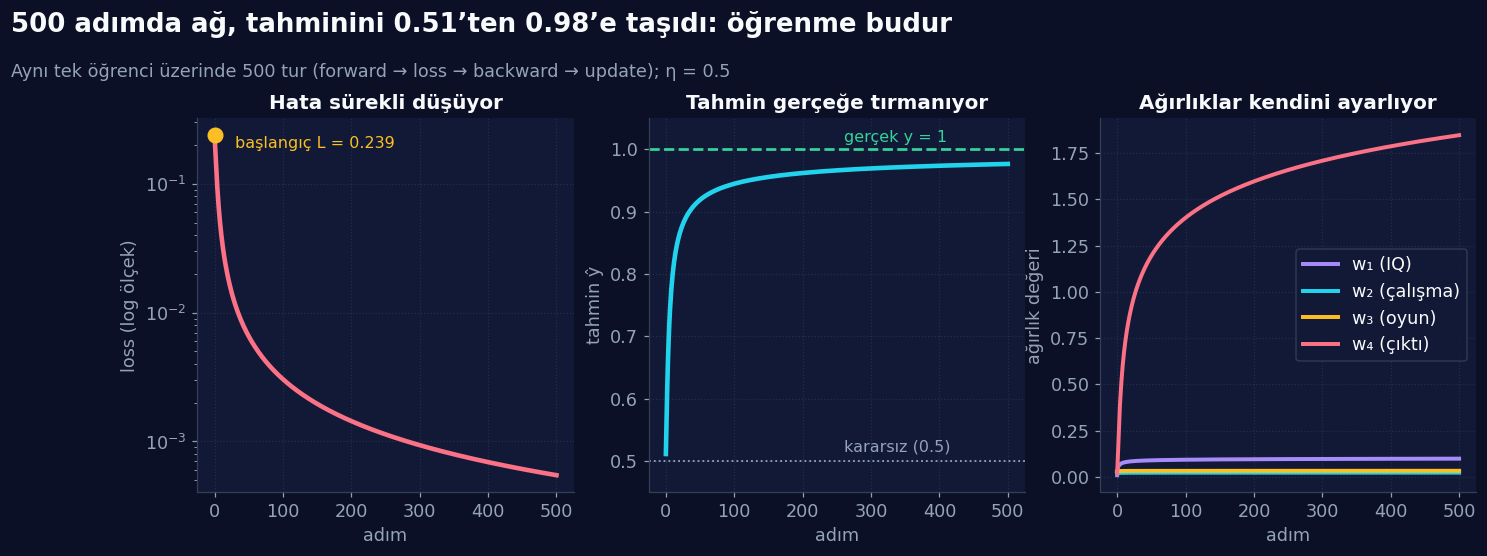

In [30]:
fig, eksenler = plt.subplots(1, 3, figsize=(15, 5.0))
adimlar = np.arange(len(G['loss']))

ax = eksenler[0]
ax.plot(adimlar, G['loss'], color=RENK['gul'], lw=3)
ax.set_yscale('log'); ax.set_xlabel('adım'); ax.set_ylabel('loss (log ölçek)'); ax.set_title('Hata sürekli düşüyor')
ax.scatter([0], [G['loss'][0]], s=90, color=RENK['amber'], zorder=5); ax.text(30, G['loss'][0] * 0.8, f'başlangıç L = {G["loss"][0]:.3f}', color=RENK['amber'], fontsize=10.5)

ax = eksenler[1]
ax.plot(adimlar, G['yhat'], color=RENK['cam'], lw=3)
ax.axhline(1.0, color=RENK['yesil'], ls='--', lw=1.8); ax.text(260, 1.012, 'gerçek y = 1', color=RENK['yesil'], fontsize=10.5)
ax.axhline(0.5, color=RENK['soluk'], ls=':', lw=1.2); ax.text(260, 0.515, 'kararsız (0.5)', color=RENK['soluk'], fontsize=10.5)
ax.set_xlabel('adım'); ax.set_ylabel('tahmin ŷ'); ax.set_title('Tahmin gerçeğe tırmanıyor'); ax.set_ylim(0.45, 1.05)

ax = eksenler[2]
for i, (renk, ad) in enumerate(zip([RENK['mor'], RENK['cam'], RENK['amber']], ['w₁ (IQ)', 'w₂ (çalışma)', 'w₃ (oyun)'])):
    ax.plot(adimlar, G['w'][:, i], color=renk, lw=2.6, label=ad)
ax.plot(adimlar, G['w4'], color=RENK['gul'], lw=2.6, label='w₄ (çıktı)')
ax.set_xlabel('adım'); ax.set_ylabel('ağırlık değeri'); ax.set_title('Ağırlıklar kendini ayarlıyor'); ax.legend(loc='center right')

baslik(fig, f'500 adımda ağ, tahminini {G["yhat"][0]:.2f}’ten {G["yhat"][-1]:.2f}’e taşıdı: öğrenme budur', 'Aynı tek öğrenci üzerinde 500 tur (forward → loss → backward → update); η = 0.5', ust=0.79)
kaydet(fig, '11_egitim_dongusu')

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="sonuc">

**İşte öğrenme!** Kimse ağa “IQ’nun ağırlığı şu olsun” demedi. Ağ **kendi hatasına bakarak** ağırlıklarını ayarladı ve tahmini `0.51`’den `0.98`’e çıkardı. Gerçek ağlar bunu **milyonlarca ağırlık** ve **binlerce örnek** için yapar; ama her adımın mantığı bu notebook’ta elle hesapladığımızla birebir aynıdır.

**Not:** Tek bir öğrenciye bakarak eğitiyoruz; bu yüzden amaç iyi bir model kurmak değil, mekanizmayı görmek. Gerçek eğitimde yüzlerce örnek kullanılır.

</td></tr></table>

### 🎲 Ağırlıkları Aynı Başlatırsak Eğitimde Ne Olur?

Bölüm 8’de “aynı başlatma = klon çalışanlar” demiştik. Şimdi **eğitim sırasında** da kanıtlayalım: 2 gizli nöronlu bir mini ağı iki farklı şekilde başlatıp 300 adım eğitelim.

In [31]:
def mini_egit(W1, b1, w2, b2, x, y, eta, adim):
    """2 gizli nöronlu ağ: x(3) → W1(2×3) → sigmoid → w2(2) → sigmoid → ŷ"""
    W1, b1, w2 = W1.copy(), b1.copy(), w2.copy()
    for _ in range(adim):
        o = sigmoid(W1 @ x + b1)
        yh = sigmoid(o @ w2 + b2)
        d2 = -2 * (y - yh) * yh * (1 - yh)
        d1 = d2 * w2 * o * (1 - o)
        W1 -= eta * np.outer(d1, x); b1 -= eta * d1
        w2 -= eta * d2 * o; b2 -= eta * d2
    return W1, yh

# 1) Hepsi aynı değerle başlatılmış
W_a, yh_a = mini_egit(np.full((2, 3), 0.01), np.zeros(2), np.array([0.5, 0.5]), 0.0, x_ogr, y_ogr, 0.5, 300)
# 2) Küçük rastgele değerlerle başlatılmış
rng = np.random.default_rng(3)
W_b, yh_b = mini_egit(rng.normal(0, 0.02, (2, 3)), np.zeros(2), rng.normal(0, 0.5, 2), 0.0, x_ogr, y_ogr, 0.5, 300)

print('AYNI başlatma  → 1. nöron:', np.round(W_a[0], 4))
print('                 2. nöron:', np.round(W_a[1], 4))
print('                 İki nöron hâlâ birebir aynı mı?', np.allclose(W_a[0], W_a[1]))
print()
print('RASTGELE başlatma → 1. nöron:', np.round(W_b[0], 4))
print('                    2. nöron:', np.round(W_b[1], 4))
print('                    İki nöron hâlâ birebir aynı mı?', np.allclose(W_b[0], W_b[1]))

AYNI başlatma  → 1. nöron: [0.6625 0.0375 0.0375]
                 2. nöron: [0.6625 0.0375 0.0375]
                 İki nöron hâlâ birebir aynı mı? True

RASTGELE başlatma → 1. nöron: [-0.2809 -0.0647 -0.0052]
                    2. nöron: [-0.3024 -0.0213 -0.0166]
                    İki nöron hâlâ birebir aynı mı? False


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**Simetri kanıtlandı:** aynı başlayan iki nöron, her adımda **tıpatıp aynı gradyanı** aldığı için sonsuza dek aynı kalır, yani bir tanesi gereksizdir. Rastgele başlatma bu simetriyi baştan bozar; böylece her nöron **farklı bir şey** öğrenebilir.

</td></tr></table>

<a id="b12"></a>

<p align="center"><img src="assets/bolum_12.svg" width="100%" alt="Bölüm 12 — Vanishing Gradient"></p>

### 🎭 Benzetme: Fısıltı Oyunu

İlk kişi bir cümleyi fısıldar, ikinci kişi biraz daha kısık sesle tekrarlar, üçüncü daha da kısar… Son kişiye geldiğinde **ses neredeyse tamamen kaybolmuştur.** Derin ağlarda da **gradyan**, katmanlar boyunca geriye iletilirken kaybolur. Buna **Vanishing Gradient Problem (kaybolan gradyan problemi)** denir. Sonuç: ağırlıklar güncellenemez ve model **öğrenme kapasitesini** ciddi biçimde yitirir.

<p align="center"><img src="assets/fisilti_oyunu.svg" width="100%" alt="Animasyon: fısıltı oyunu, her katmanda ses çeyreğe düşer"></p>

### 🔎 Suçlu: Sigmoid’in Türevi

Aktivasyon olarak **sigmoid** kullandığımızda, zincir kuralı gereği gradyan hesabının içine **sigmoid’in türevi** girer. Yani ağırlıkların güncellenme miktarı doğrudan bu türevle **çarpılır.** Sigmoid’in türevi:

> **σ′(z) = σ(z) · (1 − σ(z))**  ve her zaman  **0 ≤ σ′(z) ≤ 0.25**

Yani her katmanda gradyan **en fazla 0.25 ile ölçeklenir.** Bunu doğrulayalım:

σ′(z) en büyük değeri : 0.2500   (z = 0.01 noktasında)
σ′(z) en küçük değeri : 0.000335  (z = ±8 civarı)


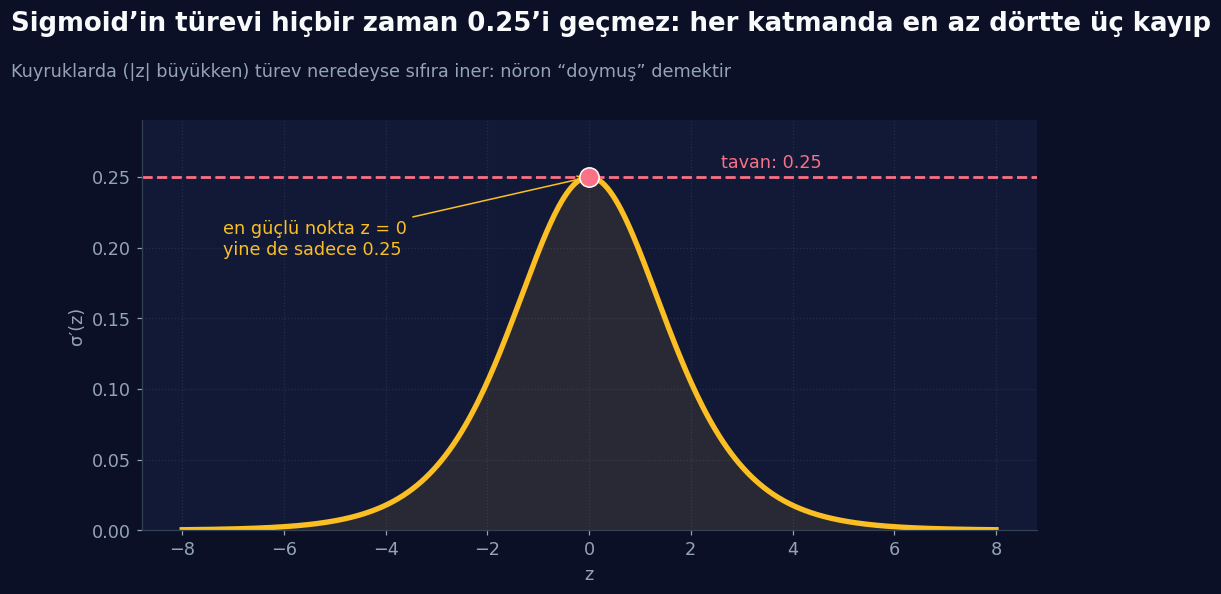

In [32]:
z_ekseni = np.linspace(-8, 8, 600)
turev = sigmoid_turev(z_ekseni)
print(f'σ′(z) en büyük değeri : {turev.max():.4f}   (z = {z_ekseni[turev.argmax()]:.2f} noktasında)')
print(f'σ′(z) en küçük değeri : {turev.min():.6f}  (z = ±8 civarı)')

fig, ax = plt.subplots(figsize=(10.5, 5.4))
ax.plot(z_ekseni, turev, color=RENK['amber'], lw=3.5)
ax.fill_between(z_ekseni, 0, turev, color=RENK['amber'], alpha=0.10)
ax.axhline(0.25, color=RENK['gul'], ls='--', lw=1.8)
ax.text(2.6, 0.2565, 'tavan: 0.25', color=RENK['gul'], fontsize=11.5)
ax.scatter([0], [0.25], s=160, color=RENK['gul'], edgecolor='white', zorder=5)
ax.annotate('en güçlü nokta z = 0\nyine de sadece 0.25', (0, 0.25), xytext=(-7.2, 0.195), color=RENK['amber'], fontsize=11.5, arrowprops=dict(arrowstyle='->', color=RENK['amber']))
ax.set_xlabel('z'); ax.set_ylabel('σ′(z)'); ax.set_ylim(0, 0.29)
baslik(fig, 'Sigmoid’in türevi hiçbir zaman 0.25’i geçmez: her katmanda en az dörtte üç kayıp', 'Kuyruklarda (|z| büyükken) türev neredeyse sıfıra iner: nöron “doymuş” demektir', ust=0.80)
kaydet(fig, '12_sigmoid_turevi')

### ✖️ Küçük Sayıları Çarpmak: Zincir Neden Çöküyor?

Gradyan, zincir kuralıyla **çarpımlar** halinde hesaplanır. 3 katmanlı bir ağda kaynaktaki gibi:

> ∂L/∂w₁ = ∂L/∂o₃ · ∂o₃/∂o₂ · ∂o₂/∂o₁ · ∂o₁/∂w₁

Buradaki her terim sigmoid türevi içerdiği için **her seferinde [0, 0.25] aralığında bir sayıyla** çarpılır. Katman sayısı arttıkça bu çarpım **katlanarak** küçülür. En iyi durumda (her çarpan tam 0.25) bile:

In [33]:
n = np.arange(1, 11)
cizelge = pd.DataFrame({'Katman sayısı (n)': n, 'En iyi durum çarpanı (0.25ⁿ)': [f'{0.25 ** k:.2e}' for k in n],
                        'Kalan oran': [f'1 / {4 ** k}' for k in n]}).set_index('Katman sayısı (n)')
display(cizelge)

,En iyi durum çarpanı (0.25ⁿ),Kalan oran
Katman sayısı (n),,
1,2.50e-01,1 / 4
2,6.25e-02,1 / 16
3,1.56e-02,1 / 64
4,3.91e-03,1 / 256
5,9.77e-04,1 / 1024
6,2.44e-04,1 / 4096
7,6.10e-05,1 / 16384
8,1.53e-05,1 / 65536
9,3.81e-06,1 / 262144


<p align="center"><img src="assets/vanishing_zinciri.svg" width="100%" alt="Animasyon: gradyan geriye giderken her katmanda küçülür"></p>

### 🛑 Öğrenme Neden Duruyor?

Ağırlık güncelleme kuralı: **w(t+1) = w(t) − η · ∂L/∂w.** Gradyan ≈ 0 olursa ağırlık değişmez: `w(t+1) ≈ w(t)`. Yani **model öğrenmeyi bırakır.** 10 katmanlı bir ağın ilk katmanındaki bir ağırlığı düşünelim:

In [34]:
w_ilk_katman = 0.5000000000
eta = 0.1
gradyan_10_katman = 0.25 ** 10          # en iyi durumda bile ~ 9.5e-7
w_yeni = w_ilk_katman - eta * gradyan_10_katman

print(f'Gradyan                 : {gradyan_10_katman:.2e}')
print(f'Ağırlık güncelleme      : {eta * gradyan_10_katman:.2e}')
print(f'w (önce)  = {w_ilk_katman:.10f}')
print(f'w (sonra) = {w_yeni:.10f}   ← neredeyse hiç değişmedi')

Gradyan                 : 9.54e-07
Ağırlık güncelleme      : 9.54e-08
w (önce)  = 0.5000000000
w (sonra) = 0.4999999046   ← neredeyse hiç değişmedi


### 🧪 Gerçek Bir Deney: 10 Katmanlı Sigmoid ve ReLU Ağında Gradyanlar

Teoriyi şimdi **ölçelim.** Aynı veriyi 10 gizli katmanlı iki ağa veriyoruz; biri **sigmoid**, diğeri **ReLU** (Bölüm 13’te anlatacağız) kullanıyor. Geri yayılımı elle yazıp **her katmandaki ortalama gradyan büyüklüğünü** ölçüyoruz (20 farklı rastgele başlangıcın ortalaması). Katman 1 = girdiye en yakın, katman 10 = çıktıya en yakın.

In [35]:
def derin_ag_gradyanlari(aktivasyon, derinlik=10, genislik=16, tohum=0, baslatma='xavier'):
    """Derin bir ağda her katmanın ağırlık gradyanının ortalama büyüklüğü (|∂L/∂W|)."""
    rng = np.random.default_rng(tohum)
    X_ = rng.normal(size=(64, genislik)); Y_ = rng.normal(size=(64, 1))
    olcek = np.sqrt(2 / genislik) if baslatma == 'he' else np.sqrt(1 / genislik)
    Ws = [rng.normal(0, olcek, size=(genislik, genislik)) for _ in range(derinlik)]
    W_cikis = rng.normal(0, olcek, size=(genislik, 1))
    act = sigmoid if aktivasyon == 'sigmoid' else (lambda z: np.maximum(z, 0))
    dact = sigmoid_turev if aktivasyon == 'sigmoid' else (lambda z: (z > 0).astype(float))

    A, Z = [X_], []
    for W in Ws:                                   # ileri geçiş
        Z.append(A[-1] @ W); A.append(act(Z[-1]))
    cikis = A[-1] @ W_cikis
    dA = (2 * (cikis - Y_) / len(Y_)) @ W_cikis.T  # çıktıdan geriye ilk adım
    normlar = np.zeros(derinlik)
    for i in reversed(range(derinlik)):            # geri yayılım: sondan başa
        dZ = dA * dact(Z[i])
        normlar[i] = np.mean(np.abs(A[i].T @ dZ))
        dA = dZ @ Ws[i].T
    return normlar

N_TOHUM = 20
g_sigmoid = np.mean([derin_ag_gradyanlari('sigmoid', tohum=s, baslatma='xavier') for s in range(N_TOHUM)], axis=0)
g_relu = np.mean([derin_ag_gradyanlari('relu', tohum=s, baslatma='he') for s in range(N_TOHUM)], axis=0)

print('Katman:        ' + ' '.join(f'{i:>8}' for i in range(1, 11)))
print('Sigmoid ağı  : ' + ' '.join(f'{v:8.1e}' for v in g_sigmoid))
print('ReLU ağı     : ' + ' '.join(f'{v:8.1e}' for v in g_relu))
print()
print(f'Sigmoid: 1. katman / 10. katman gradyan oranı = {g_sigmoid[0] / g_sigmoid[-1]:.1e}')
print(f'ReLU   : 1. katman / 10. katman gradyan oranı = {g_relu[0] / g_relu[-1]:.1e}')

Katman:               1        2        3        4        5        6        7        8        9       10
Sigmoid ağı  :  2.3e-08  2.2e-07  9.1e-07  3.7e-06  1.6e-05  6.1e-05  2.6e-04  1.1e-03  5.2e-03  2.3e-02
ReLU ağı     :  1.3e-01  1.8e-01  2.0e-01  1.9e-01  1.8e-01  1.7e-01  1.8e-01  1.7e-01  1.9e-01  2.0e-01

Sigmoid: 1. katman / 10. katman gradyan oranı = 1.0e-06
ReLU   : 1. katman / 10. katman gradyan oranı = 6.4e-01


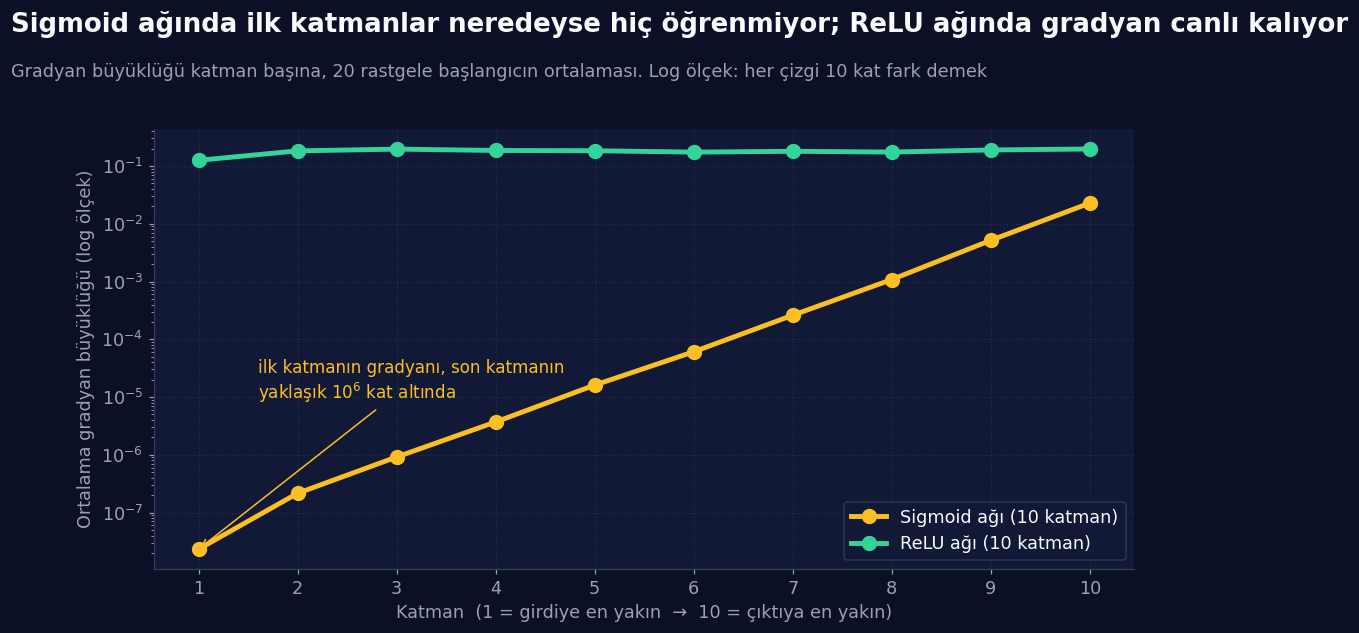

In [36]:
katmanlar = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(11.5, 5.8))
ax.plot(katmanlar, g_sigmoid, '-o', color=RENK['amber'], lw=3.2, ms=9, label='Sigmoid ağı (10 katman)')
ax.plot(katmanlar, g_relu, '-o', color=RENK['yesil'], lw=3.2, ms=9, label='ReLU ağı (10 katman)')
ax.set_yscale('log'); ax.set_xticks(katmanlar)
ax.set_xlabel('Katman  (1 = girdiye en yakın  →  10 = çıktıya en yakın)'); ax.set_ylabel('Ortalama gradyan büyüklüğü (log ölçek)')
fark_mertebe = int(round(np.log10(g_sigmoid[-1] / g_sigmoid[0])))
ax.annotate(f'ilk katmanın gradyanı, son katmanın\nyaklaşık $10^{{{fark_mertebe}}}$ kat altında', (1, g_sigmoid[0]), xytext=(1.6, g_sigmoid[0] * 400),
            color=RENK['amber'], fontsize=11, arrowprops=dict(arrowstyle='->', color=RENK['amber']))
ax.legend(loc='lower right')
baslik(fig, 'Sigmoid ağında ilk katmanlar neredeyse hiç öğrenmiyor; ReLU ağında gradyan canlı kalıyor', 'Gradyan büyüklüğü katman başına, 20 rastgele başlangıcın ortalaması. Log ölçek: her çizgi 10 kat fark demek', ust=0.80)
kaydet(fig, '12_derin_ag_gradyanlari')

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="dikkat">

**Dürüst bir not:** `0.25ⁿ` bir **üst sınırdır**; gerçek gradyan ayrıca ağırlıkların büyüklüğüne de bağlıdır. Ağırlıklar çok büyük olursa çarpanlar 1’i aşabilir (bu tersi bir sorundur: *exploding gradient*). Yukarıdaki deneyde ağırlıkları makul ölçekte (Xavier/He) başlattık ve sigmoid ağında yine de ilk katmanın gradyanı son katmanınkinin **yaklaşık milyonda biri** (6 mertebe) kadar kalıyor, yani sorun gerçek. Not: deney bizim kurduğumuz bir oyuncak ağdır; mutlak sayılar mimariye göre değişir, ama **eğilim** kaynaktaki teoriyle birebir örtüşür.

</td></tr></table>

<a id="b13"></a>

<p align="center"><img src="assets/bolum_13.svg" width="100%" alt="Bölüm 13 — Çözüm Yolları"></p>

### 🛠️ Fısıltı Oyununu Nasıl Kurtarırız?

Kaynak dokümanda dört ana çözüm yolu sayılıyor. Hepsini fısıltı oyunu benzetmesine bağlayalım:

<table><tr>
<td width="25%" valign="top"><h4>⚡ ReLU ve türevleri</h4><i>(Leaky ReLU, Parametric ReLU)</i><br><br>Sigmoid yerine, pozitif tarafta türevi <b>tam 1</b> olan aktivasyon kullanmak.<br><br>🎭 <i>Her oyuncu mesajı <b>aynı ses seviyesinde</b> iletiyor, kısmıyor.</i></td>
<td width="25%" valign="top"><h4>🎲 Akıllı başlangıç</h4><i>(Xavier, He initialization)</i><br><br>Ağırlıkları katman boyutuna göre <b>ölçeklenmiş</b> rastgele değerlerle başlatmak.<br><br>🎭 <i>Oyunculara baştan <b>uygun ses ayarı</b> verilmesi.</i></td>
<td width="25%" valign="top"><h4>📊 Batch Normalization</h4><br>Her katmanın girdisini <b>düzenli bir ölçeğe</b> getirmek.<br><br>🎭 <i>Her istasyonda <b>ses seviyesini standartlaştıran</b> bir ayarlayıcı.</i></td>
<td width="25%" valign="top"><h4>🛗 Residual Connections</h4><i>(ResNet mimarisi)</i><br><br>Bir katmanı <b>atlayan kısayollar</b> eklemek; gradyan doğrudan geri akar.<br><br>🎭 <i>Mesajı arada kısılmadan <b>asansörle</b> ilk kişiye ulaştıran kısayol.</i></td>
</tr></table>

### ⚡ En Yaygın Çözüm: ReLU

**ReLU** (Rectified Linear Unit) çok basittir: `ReLU(z) = max(0, z)`. Negatifleri sıfırlar, pozitifleri **aynen geçirir.** Pozitif tarafta türevi **tam 1**’dir; yani çarpıldığında gradyanı küçültmez. **Leaky ReLU** ise negatif tarafta tamamen sıfırlamak yerine küçük bir eğim bırakır (burada 0.1).

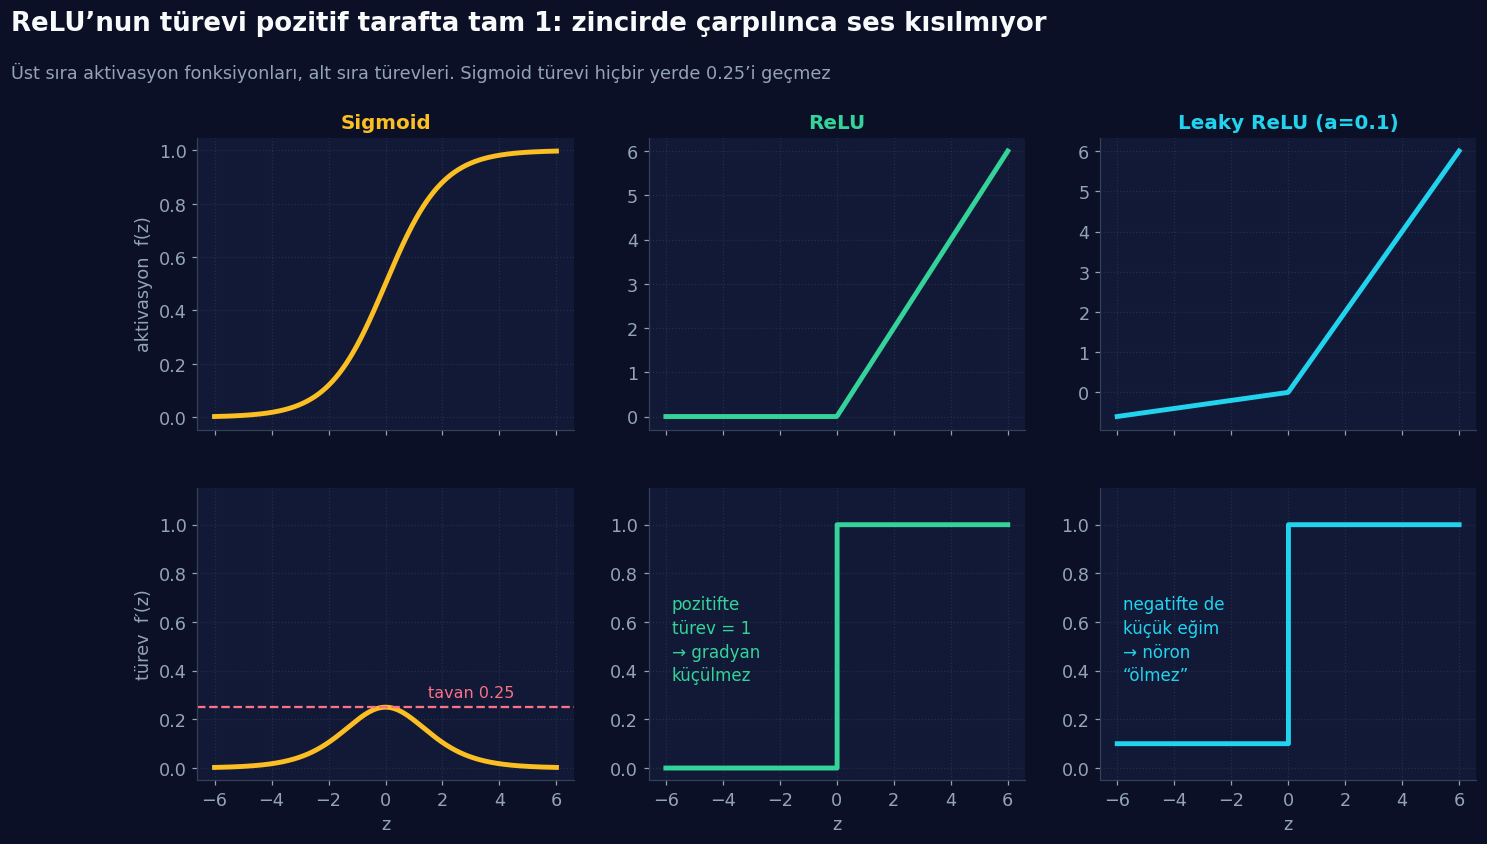

In [37]:
def relu(z):
    return np.maximum(0, z)

def relu_turev(z):
    return (np.asarray(z) > 0).astype(float)

def leaky_relu(z, a=0.1):
    return np.where(z > 0, z, a * z)

def leaky_relu_turev(z, a=0.1):
    return np.where(np.asarray(z) > 0, 1.0, a)

z_ekseni = np.linspace(-6, 6, 600)
fig, eksenler = plt.subplots(2, 3, figsize=(15, 8.0), sharex=True)
sutunlar = [('Sigmoid', sigmoid, sigmoid_turev, RENK['amber']), ('ReLU', relu, relu_turev, RENK['yesil']), ('Leaky ReLU (a=0.1)', leaky_relu, leaky_relu_turev, RENK['cam'])]
for j, (ad, f, df, renk) in enumerate(sutunlar):
    eksenler[0, j].plot(z_ekseni, f(z_ekseni), color=renk, lw=3.2); eksenler[0, j].set_title(ad, color=renk)
    eksenler[1, j].plot(z_ekseni, df(z_ekseni), color=renk, lw=3.2, drawstyle='steps-post' if 'ReLU' in ad else 'default')
    eksenler[1, j].set_xlabel('z'); eksenler[1, j].set_ylim(-0.05, 1.15)
eksenler[0, 0].set_ylabel('aktivasyon  f(z)'); eksenler[1, 0].set_ylabel('türev  f′(z)')
eksenler[1, 0].axhline(0.25, color=RENK['gul'], ls='--', lw=1.5); eksenler[1, 0].text(1.5, 0.29, 'tavan 0.25', color=RENK['gul'], fontsize=10.5)
eksenler[1, 1].text(-5.8, 0.36, 'pozitifte\ntürev = 1\n→ gradyan\nküçülmez', color=RENK['yesil'], fontsize=11, linespacing=1.4)
eksenler[1, 2].text(-5.8, 0.36, 'negatifte de\nküçük eğim\n→ nöron\n“ölmez”', color=RENK['cam'], fontsize=11, linespacing=1.4)
baslik(fig, 'ReLU’nun türevi pozitif tarafta tam 1: zincirde çarpılınca ses kısılmıyor', 'Üst sıra aktivasyon fonksiyonları, alt sıra türevleri. Sigmoid türevi hiçbir yerde 0.25’i geçmez', ust=0.84)
kaydet(fig, '13_aktivasyon_ve_turevleri')

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**Sonuç:** Sigmoid gibi türevi sınırlı fonksiyonlar kaybolan gradyanın başlıca kaynağıdır. Bu yüzden modern derin öğrenme uygulamalarında **genellikle ReLU tabanlı aktivasyonlar** tercih edilir. (Sigmoid ise hâlâ **ikili sınıflandırmanın çıktı katmanında** kullanışlıdır, çünkü sonucu 0–1 arası olasılığa çevirir.)

**Küçük uyarı:** Düz ReLU, negatif tarafta türevi 0 olduğu için bazı nöronları “ölü” bırakabilir; **Leaky ReLU** ve **Parametric ReLU** bu yüzden vardır.

</td></tr></table>

<a id="b14"></a>

<p align="center"><img src="assets/bolum_14.svg" width="100%" alt="Bölüm 14 — Kapanış"></p>

### 📚 Büyük Özet: Dört Perde, Tek Hikâye

| Perde | Kavram | Tek cümlelik özet | Günlük hayat benzetmesi |
|:--|:--|:--|:--|
| **1. Perceptron** | Tek nöron | `z = w₁x₁ + w₂x₂ + b`, sonra aktivasyon | Tek jüri üyesi |
| | Ağırlık | Girdinin önemi | Dersin kredisi |
| | Bias | Karar çizgisini kaydıran sabit | Geçme barajı |
| | Aktivasyon | Ham skoru karara çevirir | Işık anahtarı / dimmer |
| | Sınırı | Sadece doğrusal ayrım (tek doğru) | Tek cetvel |
| **2. ANN** | Katmanlar | Girdi → gizli → çıktı | Stajyer → müdür → genel müdür |
| | Forward propagation | Veri soldan sağa işlenir, `ŷ` çıkar | Sipariş akışı |
| | Rastgele başlatma | Simetriyi bozar | Klon çalışanlar olmasın |
| **3. Öğrenme** | Loss | `L = (y − ŷ)²`, tek bir hata sayısı | Dart atışında uzaklık |
| | Gradient descent | `w ← w − η·∂L/∂w` | Sisli dağda vadiye iniş |
| | Learning rate | Adım boyu | Bebek adımı ↔ zıplama |
| | Backpropagation + zincir kuralı | Her ağırlığın suçunu geriye doğru çarparak bul | Dişli kutusu / iade takibi |
| **4. Sorun** | Vanishing gradient | `σ′ ≤ 0.25` her katmanda çarpılır, gradyan kaybolur | Fısıltı oyunu |
| | Çözümler | ReLU, He/Xavier, BatchNorm, ResNet | Net ses, ses ayarı, asansör |

### 🃏 Flashcard Izgarası (Cevabı kapat, kendin söyle!)

<table><tr>
<td width="33%" valign="top"><b>❓ Perceptron kaç katmanlıdır, neden?</b><br><br>👉 Tek katmanlı. Girdi sadece veriyi taşır, hesap yalnızca tek nöronda olur.</td>
<td width="33%" valign="top"><b>❓ Bias olmasaydı ne olurdu?</b><br><br>👉 Karar çizgisi orijinden geçmek zorunda kalır; model esnekliğini kaybeder.</td>
<td width="33%" valign="top"><b>❓ Aktivasyon neden gerekli?</b><br><br>👉 Ham skoru karara çevirir; doğrusal olmayanlar ağa karmaşık şekilleri öğrenme gücü verir.</td>
</tr><tr>
<td width="33%" valign="top"><b>❓ Forward propagation nedir?</b><br><br>👉 Girdilerin ağ içinde soldan sağa işlenip tahmine dönüşmesi.</td>
<td width="33%" valign="top"><b>❓ Türev bize ne söyler?</b><br><br>👉 Ağırlığı hangi yöne oynatırsak loss’un azalacağını.</td>
<td width="33%" valign="top"><b>❓ Zincir kuralı ne işe yarar?</b><br><br>👉 Loss’un ağırlığa dolaylı bağlantısını, halkaların türevlerini çarparak bulur.</td>
</tr></table>

<table><tr><td>

<img src="assets/etiket_soru.svg" height="34" alt="soru">

**Mini sınav:** önce kendin cevapla, sonra ▶ okuna tıklayıp kontrol et.

<details><summary><b>1.</b> <code>w₁ = 0.04, w₂ = 0.6, b = −5</code> iken IQ = 90, çalışma = 5 saat olan öğrencinin <code>z</code> değeri ve step kararı nedir?</summary><br>
<code>z = 0.04·90 + 0.6·5 − 5 = 3.6 + 3.0 − 5 = 1.6</code> → <code>z &gt; 0</code> olduğu için <b>1 (geçti)</b>.</details>

<details><summary><b>2.</b> Perceptron neden XOR problemini çözemez?</summary><br>
Çünkü perceptron <b>tek bir doğru</b> çizer; XOR’daki iki sınıfı tek doğruyla ayırmak mümkün değildir (doğrusal ayrılamaz problem).</details>

<details><summary><b>3.</b> Aktivasyon fonksiyonu olmasaydı art arda 5 katman koymanın bir faydası olur muydu?</summary><br>
Hayır. Doğrusal katmanlar art arda dizilse de matematiksel olarak <b>tek bir doğrusal katmana</b> indirgenir (Bölüm 5’teki ek deney).</details>

<details><summary><b>4.</b> Ağırlıkların hepsini sıfırdan (veya aynı değerden) başlatmak neden kötü?</summary><br>
Tüm nöronlar aynı gradyanı alır ve <b>aynı şeyi öğrenir</b>; simetri bozulmaz, gizli nöron sayısı fiilen 1’e düşer.</details>

<details><summary><b>5.</b> Loss = (y − ŷ)² iken y = 1 ve ŷ = 0.8 ise loss kaçtır?</summary><br>
<code>(1 − 0.8)² = 0.04</code></details>

<details><summary><b>6.</b> Türev (∂L/∂w) pozitifse ağırlığı artırmalı mıyız azaltmalı mıyız?</summary><br>
<b>Azaltmalıyız.</b> Pozitif eğim, ağırlığı artırdıkça loss’un arttığını söyler; <code>w_yeni = w_eski − η·türev</code> ağırlığı zaten azaltır.</details>

<details><summary><b>7.</b> Learning rate çok büyük seçilirse ne olur?</summary><br>
Adımlar vadiyi <b>ıskalar</b>; ağırlık iki yamaç arasında zıplar, hatta loss büyüyerek <b>ıraksayabilir</b> (Bölüm 10’daki η = 1.1 deneyi).</details>

<details><summary><b>8.</b> Gizli katmandaki bir ağırlığın gradyanında çıktı katmanındakine göre neden daha fazla çarpan vardır?</summary><br>
Hata o ağırlığa ulaşana kadar <b>daha çok halkadan</b> geçer (w₁ → z₁ → o₁ → z₂ → ŷ → L); zincirde her halka bir çarpandır.</details>

<details><summary><b>9.</b> Sigmoid türevinin alabileceği en büyük değer nedir ve bu neden sorun yaratır?</summary><br>
<b>0.25</b> (z = 0’da). Her katmanda gradyan en fazla 0.25 ile çarpıldığı için derin ağlarda çarpım katlanarak küçülür: <b>vanishing gradient</b>.</details>

<details><summary><b>10.</b> Kaybolan gradyanın dört çözüm yolunu say.</summary><br>
(1) ReLU ve türevleri (Leaky/Parametric ReLU), (2) iyi ağırlık başlatma (Xavier, He), (3) Batch Normalization, (4) Residual connections (ResNet).</details>

</td></tr></table>

<table><tr><td>

<img src="assets/etiket_gorev.svg" height="34" alt="gorev">

**Kendi başına yap (kodu değiştirerek):**

1. **Eşik hesabı:** `w₁ = 0.04, w₂ = 0.6, b = −5` ile **IQ = 100** olan bir öğrenci en az **kaç saat** çalışırsa `z > 0` olur? (`0.04·100 + 0.6·h − 5 > 0` denklemini çöz, sonra kodla doğrula.)
2. **Öğrenme oranı keşfi:** Bölüm 11’deki eğitimi `ETA = 0.01`, `0.1`, `2.0` ile yeniden çalıştır. 500 adım sonunda `ŷ` ne oluyor? Hangisi en hızlı, hangisi en yavaş?
3. **Derinlik deneyi:** `derin_ag_gradyanlari` fonksiyonunu `derinlik=5` ve `derinlik=20` ile çalıştır. Sigmoid ağında ilk katman gradyanı derinlikle nasıl değişiyor?
4. **Kendi aktivasyonun:** `leaky_relu`’yu `a = 0.01` ile derin ağ deneyine ekle (aktivasyon seçeneğini genişlet) ve ReLU ile karşılaştır.
5. **Mini YBS senaryosu:** Kendi seçtiğin iki özellikle (örneğin “aylık harcama” ve “uygulamada geçirilen süre”) bir müşteri kaybı (churn) perceptron’u tasarla; ağırlıkları elle seç ve 5 müşteri için karar tablosu çıkar.

</td></tr></table>

### 🧭 Sıradaki Konular

Kaynak dokümanlar, bir sonraki adımlar olarak şunları öneriyor:

- 📏 **Loss fonksiyonları:** MSE ve Cross-Entropy farkı
- 🚦 **Aktivasyon fonksiyonları:** Sigmoid, ReLU, Softmax ayrıntılı
- 🏃 **Optimizasyon algoritmaları:** GD, SGD, Adam

Bugün yaptığımız her şeyi, bu konuların **temeli** olarak düşünebilirsin.

<p align="center"><img src="assets/kapanis.svg" width="100%" alt="Gün 1 tamamlandı"></p>

In [38]:
# Bu notebook'un ürettiği dosyalar
dosyalar = sorted(p for p in FIG_DIR.iterdir() if p.is_file())
for p in dosyalar:
    print(f'{p.name:<38} {p.stat().st_size / 1024:>7.0f} KB')
print(f'\nToplam: {len(dosyalar)} dosya · {sum(p.stat().st_size for p in dosyalar) / 1024:.0f} KB  →  {FIG_DIR}')

01_ic_ice_halkalar.png                     130 KB
04_bias_karar_cizgisi.png                  171 KB
05_step_ve_sigmoid.png                     137 KB
06_dogrusal_siniflandirma.png              162 KB
06_xor_dogrusal_degil.png                  156 KB
09_loss_egrisi.png                         114 KB
10_gradient_descent.gif                    161 KB
10_ogrenme_orani_deneyi.png                160 KB
10_turev_yon_gosterir.png                  121 KB
11_egitim_dongusu.png                      174 KB
12_derin_ag_gradyanlari.png                154 KB
12_sigmoid_turevi.png                      112 KB
13_aktivasyon_ve_turevleri.png             188 KB

Toplam: 13 dosya · 1939 KB  →  outputs\figures


<table><tr><td>

<img src="assets/etiket_kaynak.svg" height="34" alt="kaynak">

### 📚 Kaynak ve Atıf

Bu defterdeki notlar, **Atıl SAMANCIOĞLU**’nun **“Derin Öğrenme 2026: 100 Günlük Kamp”** adlı **Udemy** kursundan alıntıdır. Konu başlıkları, örnek sayılar (öğrenci verisi, `w₁=0.04`, `z=1.4`, `z₁=1.151`, `ŷ≈0.511` vb.) ve kavramsal çerçeve kursun ders dokümanlarına (*Perceptron*, *ANN Giriş*, *Backpropagation ve Chain Rule*, *Vanishing Gradient Problemi*) aittir.

Bu notebook’taki **günlük hayat benzetmeleri, animasyonlu diyagramlar, kod deneyleri ve ek örnekler** (XOR, simetri deneyi, derin ağ gradyan ölçümü, sayısal türev kontrolü) öğrenme amacıyla ayrıca hazırlanmıştır. Tüm hakları kurs sahibine aittir.

**Derin Öğrenme 80 Günlük Bootcamp · Gün 1**

</td></tr></table>